# Training counterspeech classifier

In [ ]:
!pip install pandas numpy matplotlib tqdm seaborn scikit-learn transformers torch

#or make virtual environment and install the packages there

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 42.0 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 149.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 243.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 138.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 167.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 693.4/693.4 kB 330.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 294.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 359.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.3/532.3 MB 119.3 MB/s  0:00:030:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/366.2 MB 221.3 MB/s  0:00:010:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 235.5 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
#to clear cuda (GPU) memory

!export PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True

#restart kernel after

## Prepare data

In [2]:
import pandas as pd

# English data (to train english models)
eng_dan_data = pd.read_csv('/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/merged_big_wref.csv')
# Drop col where language is danish
eng_data = eng_dan_data[eng_dan_data['lang'] == 'eng']

# English + danish data (to train multilingual models)
eng_dan_data = pd.read_csv('/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/merged_big_wref.csv')


In [6]:
# Count max + min + mean char & tokens of the text (on eng_dan_data df)
# Use the XLM tokenizer 
# On the rep_text alone
# And on the rep_text + ref_text combined by a [SEP] token 


from transformers import AutoTokenizer
import pandas as pd
import numpy as np
from tqdm import tqdm

tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-large")

# Make sure text columns are strings
rep_texts = eng_dan_data["rep_text"].fillna("").astype(str).tolist()
ref_texts = eng_dan_data["ref_text"].fillna("").astype(str).tolist()

def summarize_lengths(name, char_lengths, token_lengths):
    print(f"\n{name}")
    print("Characters:")
    print(f"  min:  {np.min(char_lengths)}")
    print(f"  mean: {np.mean(char_lengths):.2f}")
    print(f"  max:  {np.max(char_lengths)}")
    print("Tokens:")
    print(f"  min:  {np.min(token_lengths)}")
    print(f"  mean: {np.mean(token_lengths):.2f}")
    print(f"  max:  {np.max(token_lengths)}")

# 1) rep_text alone
rep_char_lengths = [len(x) for x in rep_texts]
rep_token_lengths = [
    len(tokenizer.tokenize(x))
    for x in tqdm(rep_texts, desc="Tokenizing rep_text")
]

summarize_lengths("rep_text alone", rep_char_lengths, rep_token_lengths)

# 2) ref_text + rep_text as used in training
combined_char_lengths = [
    len(ref) + len(str(tokenizer.sep_token)) + len(rep)
    for ref, rep in zip(ref_texts, rep_texts)
]

combined_token_lengths = []

for ref, rep in tqdm(zip(ref_texts, rep_texts), total=len(rep_texts), desc="Tokenizing ref_text + rep_text"):
    enc = tokenizer(
        ref,
        rep,
        add_special_tokens=True,
        truncation=False
    )
    combined_token_lengths.append(len(enc["input_ids"]))

summarize_lengths(
    "ref_text + rep_text combined",
    combined_char_lengths,
    combined_token_lengths
)

Tokenizing rep_text: 100%|██████████| 7388/7388 [00:00<00:00, 21722.65it/s]



rep_text alone
Characters:
  min:  5
  mean: 120.53
  max:  588
Tokens:
  min:  2
  mean: 32.03
  max:  176


Tokenizing ref_text + rep_text: 100%|██████████| 7388/7388 [00:00<00:00, 9656.43it/s]


ref_text + rep_text combined
Characters:
  min:  33
  mean: 307.19
  max:  3625
Tokens:
  min:  14
  mean: 84.14
  max:  875


## Train models

The base models are of different types (architechtures). The code takes this into account. E.g. if the model is a classification model like DEBATE, the argument 'ignore_mismatched_sizes=True' is needed to ignore the classification head of the initiated model since there will be a mismatch of my classification head (having 9 labels) and their (often fewer labels). If the model is of type 'FILL-mask', this is e.g. not needed 

### Multilingual models

#### xlm-roberta-large

- https://huggingface.co/FacebookAI/xlm-roberta-large
- Multilingual
- 0.6B params
- Fill-mask type
- Encoder-only

##### Without ref

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 15820.35it/s]
XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  9.06it/s]


  Train Loss: 0.7979, test Loss: 0.7143
  Hateful Accuracy: 0.7788, Constructive Accuracy: 0.7415, Agree Accuracy: 0.5419
  Average Accuracy: 0.6870
Epoch 2:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  9.03it/s]


  Train Loss: 0.6823, test Loss: 0.6239
  Hateful Accuracy: 0.7977, Constructive Accuracy: 0.8620, Agree Accuracy: 0.5751
  Average Accuracy: 0.7450
Epoch 3:
Being trained with a learning rate of 2e-06


... (20 outputs left out)

Evaluating: 100%|██████████| 93/93 [00:10<00:00,  9.07it/s]


  Train Loss: 0.2797, test Loss: 0.5539
  Hateful Accuracy: 0.8559, Constructive Accuracy: 0.8701, Agree Accuracy: 0.6982
  Average Accuracy: 0.8080
Epoch 14:
Being trained with a learning rate of 5e-07


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  9.07it/s]


  Train Loss: 0.2687, test Loss: 0.5595
  Hateful Accuracy: 0.8572, Constructive Accuracy: 0.8762, Agree Accuracy: 0.6969
  Average Accuracy: 0.8100
Stopping because early stopping has been triggered.


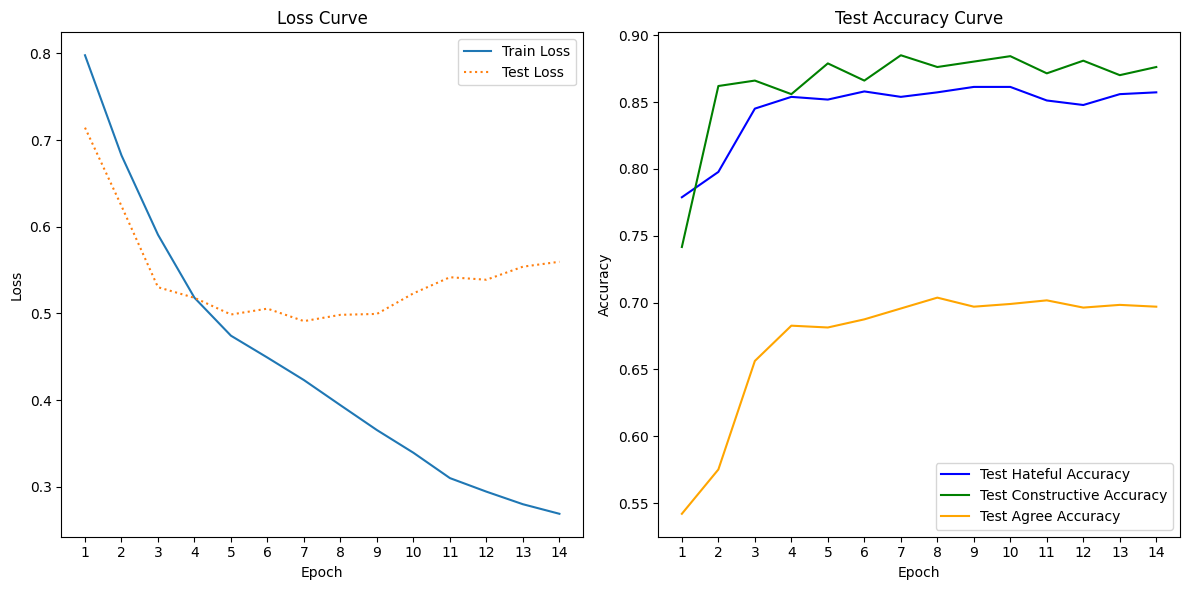

In [7]:
## --- Imports ---

# Data processing 
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
# Modelling 
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import random

'''
Implements a random seed throughout that makes the result replicable. However label smoothing can not be enabled as this messes up the seed
'''

def set_seed(seed):
    # Python's built-in random module
    random.seed(seed)
    
    # Numpy's random module
    np.random.seed(seed)
    
    # PyTorch seed for CPU
    torch.manual_seed(seed)
    
    # PyTorch seed for all GPU devices (if using CUDA)
    torch.cuda.manual_seed_all(seed)
    
    # Make sure to disable CuDNN's non-deterministic optimizations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(1)

'''
The following code will fine-tune a model on a English labeled dataset to predict 1 label for each class where:

class refers to the different ''categories'' of the data. In this case there are 3 classes: 'rep_hateful', 'rep_constructive', 'rep_agree', and 

label refers to the type of each class. In this case there are 9 labels in total, where a text can have only 1 label for each class, e.g. 'Hateful', 'Not Constructive', 'Disagree'. Thus a text cannot have both the labels 'Hateful' and 'Not Hateful'

Explanatory comments are integrated to guide users through the code structure and functionality.
'''

# Set device, run on gpu if available 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load/prepare data
train_df=eng_dan_data.sample(frac=0.8,random_state=2000) #take 80% of new df
test_df=eng_dan_data.drop(train_df.index) #take new df but to create test but drop the ones that are in train


# Set tokenizer and batch 
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-large")
batch_size = 16


# Map labels to numeric values for each of the classes 
label_mappings = {
    'rep_hateful': {'Not Hateful': 0, 'Hateful': 1, 'Unclassifiable Hateful': 2},
    'rep_constructive': {'Not Constructive': 0, 'Constructive': 1, 'Unclassifiable Constructive': 2},
    'rep_agree': {'Agree': 0, 'Disagree': 1, 'Unclear': 2}}
for column, mapping in label_mappings.items():
    train_df[column] = train_df[column].map(mapping)
    test_df[column] = test_df[column].map(mapping)


# Directly extract the necessary columns as a numpy array (already encoded as 0, 1, 2)
train_labels = train_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values
test_labels = test_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values


# Define class
class TextDataset(Dataset):
    def __init__(self, texts, labels_hateful, labels_constructive, labels_agree, tokenizer, max_length = 512):
        self.texts = texts
        self.labels_hateful = labels_hateful
        self.labels_constructive = labels_constructive
        self.labels_agree = labels_agree
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts) # Returns the size of the dataset

    def __getitem__(self, idx):
        text = self.texts[idx]
        # Get labels for each class
        label_hateful = self.labels_hateful[idx]
        label_constructive = self.labels_constructive[idx]
        label_agree = self.labels_agree[idx]

        # Tokenize the text
        encodings = self.tokenizer(
            text,
            padding = "max_length",
            truncation = True,
            max_length = self.max_length,
            return_tensors = "pt")

        # Return input tensors and labels for each class
        return {
            "input_ids": encodings["input_ids"].squeeze(),  # Squeeze function converts to the correct shape
            "attention_mask": encodings["attention_mask"].squeeze(),
            "labels_hateful": torch.tensor(label_hateful, dtype = torch.long), # Convert labels into tensor format
            "labels_constructive": torch.tensor(label_constructive, dtype = torch.long), # Long function to get 64-bit integer numbers 
            "labels_agree": torch.tensor(label_agree, dtype = torch.long)}


# Prepare datasets using the TextDataset class we definedd
train_dataset = TextDataset(
    texts = train_df['rep_text'].tolist(),
    labels_hateful = train_labels[:, 0], # Get first column from train_labels array
    labels_constructive = train_labels[:, 1],
    labels_agree = train_labels[:, 2],
    tokenizer = tokenizer)

test_dataset = TextDataset(
    texts = test_df['rep_text'].tolist(),
    labels_hateful = test_labels[:, 0], # Get first column from train_labels array
    labels_constructive = test_labels[:, 1],
    labels_agree = test_labels[:, 2],
    tokenizer = tokenizer)


# Create train and test dataloaders
# Dataset stores the texts and their corresponding labels
# DataLoader wraps an iterable around the Dataset to enable easy access to the texts
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = batch_size)


# Set model
model = AutoModelForSequenceClassification.from_pretrained("xlm-roberta-large", num_labels = 9)

# Set criterion: CrossEntropyLoss used for multi output classification. This criterion computes the cross entropy loss between input logits and target
#criterion = nn.CrossEntropyLoss(label_smoothing=0.3)
criterion = nn.CrossEntropyLoss()

# Set optimizer, Adam works well for most tasks
optimizer = optim.AdamW(model.parameters(), lr = 2e-6, weight_decay=1e-1) 
# Define learning rete scheduler 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5, min_lr=1e-7)


# Define training process. The model is set up as a multi-output classification task where each label is independently predicted
def train(model, dataloader, criterion, optimizer, device):
    model.train() # Set to train mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0 # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class
    
    for batch in tqdm(dataloader, desc = "Training"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels_hateful = batch["labels_hateful"].to(device)
        labels_constructive = batch["labels_constructive"].to(device)
        labels_agree = batch["labels_agree"].to(device)
        
        # Clear out the gradients of all parameters that the optimizer is tracking
        optimizer.zero_grad()
        # Calls the forward pass of the model and processes the input data through the layers of the model
        outputs = model(input_ids, attention_mask = attention_mask)
        
        # Extract logits (raw predictions before applying any activation function)
        # Logits will have a shape of [batch_size, 9] since num_labels = 9
        logits = outputs.logits 

        # Now fetch the logits for each label
        # Split the logits into 3 sets of logits (each corresponding to 1 task with 3 labels)
        logits_hateful = logits[:, :3]           # First 3 logits for the "hateful" task
        logits_constructive = logits[:, 3:6]     # Next 3 logits for the "constructive" task
        logits_agree = logits[:, 6:]             # Last 3 logits for the "agree" task

        # Calculate the loss for each class
        # The criterion (CrossEntropyLoss) applies the softmax function internally to the logits. This transforms the raw logits into probabilities that sum to 1 for each example in the batch. 
        # It then calculates the negative log-likelihood loss based on the true labels
        loss_hateful = criterion(logits_hateful, labels_hateful)
        loss_constructive = criterion(logits_constructive, labels_constructive)
        loss_agree = criterion(logits_agree, labels_agree)

        # Combine the losses (average them)
        loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
        
        # Accumulate the loss as a Python float
        total_loss += loss.item()
        
        # Backward pass and optimizer step
        loss.backward()
        optimizer.step() # Makes the optimizer iterate over all parameters (tensors) it is supposed to update and use their internally stored gradients to update their values.

        # Accuracy calculations
        # Predicts the labels for each task by selecting the label with the highest score (logit)
        preds_hateful = torch.argmax(logits_hateful, dim = 1)
        preds_constructive = torch.argmax(logits_constructive, dim = 1)
        preds_agree = torch.argmax(logits_agree, dim = 1)

        # Calculates how many of the predicted labels are correct and then adds that number to the correct_x counter
        correct_hateful += (preds_hateful == labels_hateful).sum().item()
        correct_constructive += (preds_constructive == labels_constructive).sum().item()
        correct_agree += (preds_agree == labels_agree).sum().item()

        # Keeps track of the total number of texts for each classification task
        total_hateful += labels_hateful.size(0) 
        total_constructive += labels_constructive.size(0)
        total_agree += labels_agree.size(0)

    # Calculate average loss for the train data
    avg_loss_train = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return avg_loss_train, accuracy_hateful, accuracy_constructive, accuracy_agree

    
# Define evaluation process
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set to evaluation mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0  # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class

    # Initalize empty list to store predicted labels and true labels
    # These will be used in making the classfication reports
    all_preds_hateful, all_preds_constructive, all_preds_agree = [],[],[]
    all_labels_hateful, all_labels_constructive, all_labels_agree = [],[],[]

    with torch.no_grad(): # Temporarily disable gradient calculations during the forward pass
        # Saves memory and computation because the operations don't need to be tracked for backward propagation.
        # This is crucial during evaluation (inference) because we don't need to update the model parameters—just forward pass predictions.
        for batch in tqdm(dataloader, desc = "Evaluating"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels_hateful = batch["labels_hateful"].to(device)
            labels_constructive = batch["labels_constructive"].to(device)
            labels_agree = batch["labels_agree"].to(device)

            # Calls the forward pass of the model and processes the input data through the layers of the model
            outputs = model(input_ids, attention_mask = attention_mask)
            # Extract logits
            logits = outputs.logits

            # Split the logits for each task
            logits_hateful = logits[:, :3]          
            logits_constructive = logits[:, 3:6] 
            logits_agree = logits[:, 6:]

            # Calculate loss for each task
            loss_hateful = criterion(logits_hateful, labels_hateful)
            loss_constructive = criterion(logits_constructive, labels_constructive)
            loss_agree = criterion(logits_agree, labels_agree)

            # Combine the losses (average them) and store as float
            loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
            total_loss += loss.item()

            # Predicts the labels for each task
            preds_hateful = torch.argmax(logits_hateful, dim=1).cpu().numpy()
            preds_constructive = torch.argmax(logits_constructive, dim=1).cpu().numpy()
            preds_agree = torch.argmax(logits_agree, dim=1).cpu().numpy()

            # Extend the predictions and true labels
            all_preds_hateful.extend(preds_hateful)
            all_preds_constructive.extend(preds_constructive)
            all_preds_agree.extend(preds_agree)

            all_labels_hateful.extend(labels_hateful.cpu().numpy()) # Use labels on CPU for comparison after moving them to device
            all_labels_constructive.extend(labels_constructive.cpu().numpy())
            all_labels_agree.extend(labels_agree.cpu().numpy())

            # Update counts for correctly predicted labels 
            correct_hateful += (preds_hateful == labels_hateful.cpu().numpy()).sum()
            correct_constructive += (preds_constructive == labels_constructive.cpu().numpy()).sum()
            correct_agree += (preds_agree == labels_agree.cpu().numpy()).sum()

            # Update counts for total number of labels for each class 
            total_hateful += labels_hateful.size(0)
            total_constructive += labels_constructive.size(0)
            total_agree += labels_agree.size(0)

    # Calculate average loss for the test data
    avg_loss_test = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return (avg_loss_test, 
            np.array(all_labels_hateful), np.array(all_preds_hateful),
            np.array(all_labels_constructive), np.array(all_preds_constructive),
            np.array(all_labels_agree), np.array(all_preds_agree),
            accuracy_hateful, accuracy_constructive, accuracy_agree)


# --- Setup saving parameters ---
output_dir = "/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/xlm/model_without_ref/"


## --- Running model ---

# Define the label classes
label_classes = { 
    'rep_hateful': ['Not Hateful', 'Hateful', 'Unclassifiable Hateful'],
    'rep_constructive': ['Not Constructive', 'Constructive', 'Unclassifiable Constructive'],
    'rep_agree': ['Agree', 'Disagree', 'Unclear']
}

train_losses, test_losses = [], [] # Empty lists for storing losses
train_accuracies, test_accuracies = [], [] # Empty lists for storing accuracies


# Number of epochs
num_epochs = 20
# Initialize counter for epoch number
epoch_no = 0 
# Empty lists for storing learning rates
lr_history = []
# Counter to track epochs with no improvement
early_stopping_counter = 0  
# Set best_loss to infinitely high to ensure that the first loss will always be lower
best_loss = float('inf')  
# Initialize best accuracy and best loss
best_avg_accuracy = 0.0
best_model_so_far = None 


for epoch in range(num_epochs):
    epoch_no = epoch + 1
    print(f"Epoch {epoch_no}:")

    # Append and print current learning rate
    lr_history.append(scheduler.get_last_lr()[0])
    print(f"Being trained with a learning rate of {lr_history[-1]}")

    # -- Train model -- 
    avg_loss_train, train_acc_hateful, train_acc_constructive, train_acc_agree = train(model, train_dataloader, criterion, optimizer, device)
    train_losses.append(avg_loss_train) # Store training loss
    train_accuracies.append((train_acc_hateful, train_acc_constructive, train_acc_agree)) # Store accuracies for training
    
    # -- Test model -- 
    avg_loss_test, test_true_labels_hateful, test_pred_labels_hateful,test_true_labels_constructive, test_pred_labels_constructive, test_true_labels_agree, test_pred_labels_agree, test_acc_hateful, test_acc_constructive, test_acc_agree =  evaluate(model, test_dataloader, criterion, device)
    test_losses.append(avg_loss_test) # Store test loss
    test_accuracies.append((test_acc_hateful, test_acc_constructive, test_acc_agree)) # Store accuracies for testing

    # Update learning rate with scheduler
    scheduler.step(avg_loss_test)

    # Save accuracy
    avg_accuracy = round((test_acc_hateful+test_acc_constructive + test_acc_agree)/3,3)
    
    # Print results 
    print(f"  Train Loss: {avg_loss_train:.4f}, test Loss: {avg_loss_test:.4f}")
    print(f"  Hateful Accuracy: {test_acc_hateful:.4f}, Constructive Accuracy: {test_acc_constructive:.4f}, Agree Accuracy: {test_acc_agree:.4f}")
    print(f"  Average Accuracy: {avg_accuracy:.4f}")


    # Save the model if it achieves the best average accuracy and stop running if accuracy has not improved 
    if avg_accuracy > best_avg_accuracy:
        best_avg_accuracy = avg_accuracy
        best_model_epoch = epoch_no 

        # Save true and predicted labels for the best model
        best_labels = {
            "hateful": {"true": test_true_labels_hateful, "pred": test_pred_labels_hateful},
            "constructive": {"true": test_true_labels_constructive, "pred": test_pred_labels_constructive},
            "agree": {"true": test_true_labels_agree, "pred": test_pred_labels_agree}
        }
        
        best_model_so_far = model.state_dict()
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1  # Increment the counter if no improvement
        if early_stopping_counter >= 4:
            print("Stopping because early stopping has been triggered.")
            break  # Stop training if patience is exceeded


# Save only the 1 best model off all when all epochs are done
checkpoint_filename = "model_epoch_{epoch}.pt"
best_model_path = output_dir + checkpoint_filename.format(epoch = best_model_epoch)
torch.save(best_model_so_far, best_model_path)


# --- Plotting results ---

# Generate confusion matrix for each class for the best model
for class_name, labels in label_classes.items():

    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Compute the confusion matrix 
        matrix = confusion_matrix(class_true, class_pred)
        # Plot and save the confusion matrix
        plt.figure(figsize = (10,10))
        sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels,
                    yticklabels=labels)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Confusion Matrix for {class_name}_')
        plt.savefig(f'{output_dir}/confusion_matrix_{class_name}_epoch_{best_model_epoch}.png')
        plt.close()


# Generate classification report for each class for the best model
for class_name, labels in label_classes.items():
    
    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Generate classification report as a dictionary
        report = classification_report(class_true, 
                                    class_pred, 
                                    target_names=labels, 
                                    output_dict=True)
        
        # Save the classification report to a text file
        report_filename = f"{output_dir}/classification_report_{class_name}_epoch_{best_model_epoch}.txt"
        with open(report_filename, "w") as f:
            f.write(classification_report(class_true, class_pred, target_names=labels))


plt.figure(figsize = (12,6))

# Loss and accuracy plot over epochs
# Loss curve
plt.subplot(1,2,1)
plt.plot(np.arange(1, epoch_no+1), train_losses, label = "Train Loss")
plt.plot(np.arange(1, epoch_no+1), test_losses, label = "Test Loss", linestyle = ":")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Accuracy on test set (colored by class)
plt.subplot(1, 2, 2)
plt.plot(np.arange(1, epoch_no+1), [x[0] for x in test_accuracies], label = "Test Hateful Accuracy", color = "blue")
plt.plot(np.arange(1, epoch_no+1), [x[1] for x in test_accuracies], label = "Test Constructive Accuracy", color = "green")
plt.plot(np.arange(1, epoch_no+1), [x[2] for x in test_accuracies], label = "Test Agree Accuracy", color = "orange")
plt.title("Test Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Save and show 
plt.savefig(output_dir+f'accuracy_and_loss_curce_plot_epoch_{best_model_epoch}.png')
plt.tight_layout()
plt.show()



##### With ref

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 15594.44it/s]
XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  8.96it/s]


  Train Loss: 0.8220, test Loss: 0.7426
  Hateful Accuracy: 0.7788, Constructive Accuracy: 0.7415, Agree Accuracy: 0.5027
  Average Accuracy: 0.6740
Epoch 2:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  8.96it/s]


  Train Loss: 0.7133, test Loss: 0.6463
  Hateful Accuracy: 0.7788, Constructive Accuracy: 0.8309, Agree Accuracy: 0.6015
  Average Accuracy: 0.7370
Epoch 3:
Being trained with a learning rate of 2e-06


... (18 outputs left out)

Evaluating: 100%|██████████| 93/93 [00:10<00:00,  8.98it/s]


  Train Loss: 0.2632, test Loss: 0.5389
  Hateful Accuracy: 0.8559, Constructive Accuracy: 0.8640, Agree Accuracy: 0.7152
  Average Accuracy: 0.8120
Epoch 13:
Being trained with a learning rate of 1e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  8.98it/s]


  Train Loss: 0.2449, test Loss: 0.5708
  Hateful Accuracy: 0.8424, Constructive Accuracy: 0.8606, Agree Accuracy: 0.7097
  Average Accuracy: 0.8040
Stopping because early stopping has been triggered.


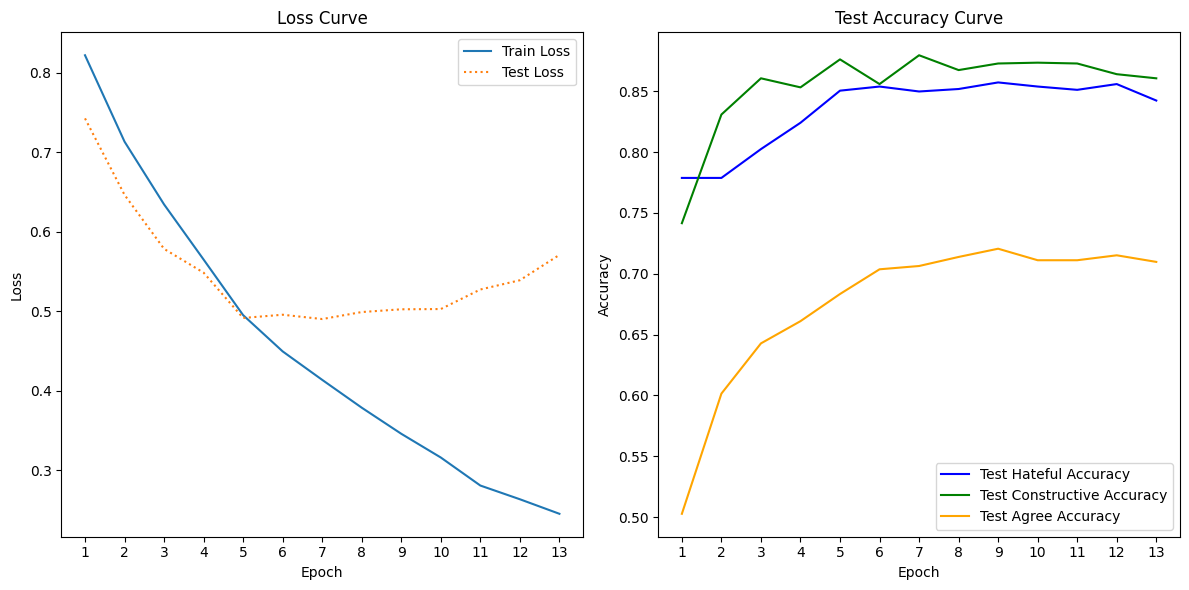

In [8]:
## --- Imports ---

# Data processing 
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
# Modelling 
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import random

'''
Implements a random seed throughout that makes the result replicable. However label smoothing can not be enabled as this messes up the seed
'''

def set_seed(seed):
    # Python's built-in random module
    random.seed(seed)
    
    # Numpy's random module
    np.random.seed(seed)
    
    # PyTorch seed for CPU
    torch.manual_seed(seed)
    
    # PyTorch seed for all GPU devices (if using CUDA)
    torch.cuda.manual_seed_all(seed)
    
    # Make sure to disable CuDNN's non-deterministic optimizations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(1)



'''
The following code will fine-tune a model on a English labeled dataset to predict 1 label for each class where:

class refers to the different ''categories'' of the data. In this case there are 3 classes: 'rep_hateful', 'rep_constructive', 'rep_agree', and 

label refers to the type of each class. In this case there are 9 labels in total, where a text can have only 1 label for each class, e.g. 'Hateful', 'Not Constructive', 'Disagree'. Thus a text cannot have both the labels 'Hateful' and 'Not Hateful'

Explanatory comments are integrated to guide users through the code structure and functionality.
'''

# Set device, run on gpu if available 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load/prepare data
train_df=eng_dan_data.sample(frac=0.8,random_state=2000) #take 80% of new df
test_df=eng_dan_data.drop(train_df.index) #take new df but to create test but drop the ones that are in train

# Set tokenizer and batch size
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-large")
batch_size = 16


# Map labels to numeric values for each of the classes 
label_mappings = {
    'rep_hateful': {'Not Hateful': 0, 'Hateful': 1, 'Unclassifiable Hateful': 2},
    'rep_constructive': {'Not Constructive': 0, 'Constructive': 1, 'Unclassifiable Constructive': 2},
    'rep_agree': {'Agree': 0, 'Disagree': 1, 'Unclear': 2}}
for column, mapping in label_mappings.items():
    train_df[column] = train_df[column].map(mapping)
    test_df[column] = test_df[column].map(mapping)


# Directly extract the necessary columns as a numpy array (already encoded as 0, 1, 2)
train_labels = train_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values
test_labels = test_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values


# Define class
class TextDataset(Dataset):
    def __init__(self, texts,ref_texts, labels_hateful, labels_constructive, labels_agree, tokenizer, max_length = 512):
        self.texts = texts
        self.ref_texts = ref_texts
        self.labels_hateful = labels_hateful
        self.labels_constructive = labels_constructive
        self.labels_agree = labels_agree
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts) # Returns the size of the dataset

    def __getitem__(self, idx):

        text = self.texts[idx]
        ref_text = self.ref_texts[idx]

        label_hateful = self.labels_hateful[idx]
        label_constructive = self.labels_constructive[idx]
        label_agree = self.labels_agree[idx]

        #the tokenizer automatically inserts the separator tokens
        encodings = self.tokenizer(
            ref_text,
            text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encodings["input_ids"].squeeze(),
            "attention_mask": encodings["attention_mask"].squeeze(),
            "labels_hateful": torch.tensor(label_hateful, dtype=torch.long),
            "labels_constructive": torch.tensor(label_constructive, dtype=torch.long),
            "labels_agree": torch.tensor(label_agree, dtype=torch.long),
        }


# Prepare datasets using the TextDataset class we definedd
train_dataset = TextDataset(
    texts = train_df['rep_text'].tolist(),
    ref_texts = train_df['ref_text'].tolist(),
    labels_hateful = train_labels[:, 0], # Get first column from train_labels array
    labels_constructive = train_labels[:, 1],
    labels_agree = train_labels[:, 2],
    tokenizer = tokenizer)


test_dataset = TextDataset(
    texts = test_df['rep_text'].tolist(),
    ref_texts = test_df['ref_text'].tolist(),
    labels_hateful = test_labels[:, 0], # Get first column from train_labels array
    labels_constructive = test_labels[:, 1],
    labels_agree = test_labels[:, 2],
    tokenizer = tokenizer)


# Create train and test dataloaders
# Dataset stores the texts and their corresponding labels
# DataLoader wraps an iterable around the Dataset to enable easy access to the texts
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = batch_size)


# Set model
model = AutoModelForSequenceClassification.from_pretrained("xlm-roberta-large", num_labels = 9)

# Set criterion: CrossEntropyLoss used for multi output classification. This criterion computes the cross entropy loss between input logits and target
#criterion = nn.CrossEntropyLoss(label_smoothing=0.3)
criterion = nn.CrossEntropyLoss()

# Set optimizer, Adam works well for most tasks
optimizer = optim.AdamW(model.parameters(), lr = 2e-6, weight_decay=1e-1) 
# Define learning rete scheduler 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5, min_lr=1e-7)


# Define training process. The model is set up as a multi-output classification task where each label is independently predicted
def train(model, dataloader, criterion, optimizer, device):
    model.train() # Set to train mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0 # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class
    
    for batch in tqdm(dataloader, desc = "Training"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels_hateful = batch["labels_hateful"].to(device)
        labels_constructive = batch["labels_constructive"].to(device)
        labels_agree = batch["labels_agree"].to(device)
        
        # Clear out the gradients of all parameters that the optimizer is tracking
        optimizer.zero_grad()
        # Calls the forward pass of the model and processes the input data through the layers of the model
        outputs = model(input_ids, attention_mask = attention_mask)
        
        # Extract logits (raw predictions before applying any activation function)
        # Logits will have a shape of [batch_size, 9] since num_labels = 9
        logits = outputs.logits 

        # Now fetch the logits for each label
        # Split the logits into 3 sets of logits (each corresponding to 1 task with 3 labels)
        logits_hateful = logits[:, :3]           # First 3 logits for the "hateful" task
        logits_constructive = logits[:, 3:6]     # Next 3 logits for the "constructive" task
        logits_agree = logits[:, 6:]             # Last 3 logits for the "agree" task

        # Calculate the loss for each class
        # The criterion (CrossEntropyLoss) applies the softmax function internally to the logits. This transforms the raw logits into probabilities that sum to 1 for each example in the batch. 
        # It then calculates the negative log-likelihood loss based on the true labels
        loss_hateful = criterion(logits_hateful, labels_hateful)
        loss_constructive = criterion(logits_constructive, labels_constructive)
        loss_agree = criterion(logits_agree, labels_agree)

        # Combine the losses (average them)
        loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
        
        # Accumulate the loss as a Python float
        total_loss += loss.item()
        
        # Backward pass and optimizer step
        loss.backward()
        optimizer.step() # Makes the optimizer iterate over all parameters (tensors) it is supposed to update and use their internally stored gradients to update their values.

        # Accuracy calculations
        # Predicts the labels for each task by selecting the label with the highest score (logit)
        preds_hateful = torch.argmax(logits_hateful, dim = 1)
        preds_constructive = torch.argmax(logits_constructive, dim = 1)
        preds_agree = torch.argmax(logits_agree, dim = 1)

        # Calculates how many of the predicted labels are correct and then adds that number to the correct_x counter
        correct_hateful += (preds_hateful == labels_hateful).sum().item()
        correct_constructive += (preds_constructive == labels_constructive).sum().item()
        correct_agree += (preds_agree == labels_agree).sum().item()

        # Keeps track of the total number of texts for each classification task
        total_hateful += labels_hateful.size(0) 
        total_constructive += labels_constructive.size(0)
        total_agree += labels_agree.size(0)

    # Calculate average loss for the train data
    avg_loss_train = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return avg_loss_train, accuracy_hateful, accuracy_constructive, accuracy_agree

    
# Define evaluation process
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set to evaluation mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0  # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class

    # Initalize empty list to store predicted labels and true labels
    # These will be used in making the classfication reports
    all_preds_hateful, all_preds_constructive, all_preds_agree = [],[],[]
    all_labels_hateful, all_labels_constructive, all_labels_agree = [],[],[]

    with torch.no_grad(): # Temporarily disable gradient calculations during the forward pass
        # Saves memory and computation because the operations don't need to be tracked for backward propagation.
        # This is crucial during evaluation (inference) because we don't need to update the model parameters—just forward pass predictions.
        for batch in tqdm(dataloader, desc = "Evaluating"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels_hateful = batch["labels_hateful"].to(device)
            labels_constructive = batch["labels_constructive"].to(device)
            labels_agree = batch["labels_agree"].to(device)

            # Calls the forward pass of the model and processes the input data through the layers of the model
            outputs = model(input_ids, attention_mask = attention_mask)
            # Extract logits
            logits = outputs.logits

            # Split the logits for each task
            logits_hateful = logits[:, :3]          
            logits_constructive = logits[:, 3:6] 
            logits_agree = logits[:, 6:]

            # Calculate loss for each task
            loss_hateful = criterion(logits_hateful, labels_hateful)
            loss_constructive = criterion(logits_constructive, labels_constructive)
            loss_agree = criterion(logits_agree, labels_agree)

            # Combine the losses (average them) and store as float
            loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
            total_loss += loss.item()

            # Predicts the labels for each task
            preds_hateful = torch.argmax(logits_hateful, dim=1).cpu().numpy()
            preds_constructive = torch.argmax(logits_constructive, dim=1).cpu().numpy()
            preds_agree = torch.argmax(logits_agree, dim=1).cpu().numpy()

            # Extend the predictions and true labels
            all_preds_hateful.extend(preds_hateful)
            all_preds_constructive.extend(preds_constructive)
            all_preds_agree.extend(preds_agree)

            all_labels_hateful.extend(labels_hateful.cpu().numpy()) # Use labels on CPU for comparison after moving them to device
            all_labels_constructive.extend(labels_constructive.cpu().numpy())
            all_labels_agree.extend(labels_agree.cpu().numpy())

            # Update counts for correctly predicted labels 
            correct_hateful += (preds_hateful == labels_hateful.cpu().numpy()).sum()
            correct_constructive += (preds_constructive == labels_constructive.cpu().numpy()).sum()
            correct_agree += (preds_agree == labels_agree.cpu().numpy()).sum()

            # Update counts for total number of labels for each class 
            total_hateful += labels_hateful.size(0)
            total_constructive += labels_constructive.size(0)
            total_agree += labels_agree.size(0)

    # Calculate average loss for the test data
    avg_loss_test = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return (avg_loss_test, 
            np.array(all_labels_hateful), np.array(all_preds_hateful),
            np.array(all_labels_constructive), np.array(all_preds_constructive),
            np.array(all_labels_agree), np.array(all_preds_agree),
            accuracy_hateful, accuracy_constructive, accuracy_agree)


# --- Setup saving parameters ---
output_dir = "/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/xlm/model_with_ref/"


## --- Running model ---

# Define the label classes
label_classes = { 
    'rep_hateful': ['Not Hateful', 'Hateful', 'Unclassifiable Hateful'],
    'rep_constructive': ['Not Constructive', 'Constructive', 'Unclassifiable Constructive'],
    'rep_agree': ['Agree', 'Disagree', 'Unclear']
}

train_losses, test_losses = [], [] # Empty lists for storing losses
train_accuracies, test_accuracies = [], [] # Empty lists for storing accuracies


# Number of epochs
num_epochs = 20
# Initialize counter for epoch number
epoch_no = 0 
# Empty lists for storing learning rates
lr_history = []
# Counter to track epochs with no improvement
early_stopping_counter = 0  
# Set best_loss to infinitely high to ensure that the first loss will always be lower
best_loss = float('inf')  
# Initialize best accuracy and best loss
best_avg_accuracy = 0.0
best_model_so_far = None 


for epoch in range(num_epochs):
    epoch_no = epoch + 1
    print(f"Epoch {epoch_no}:")

    # Append and print current learning rate
    lr_history.append(scheduler.get_last_lr()[0])
    print(f"Being trained with a learning rate of {lr_history[-1]}")

    # -- Train model -- 
    avg_loss_train, train_acc_hateful, train_acc_constructive, train_acc_agree = train(model, train_dataloader, criterion, optimizer, device)
    train_losses.append(avg_loss_train) # Store training loss
    train_accuracies.append((train_acc_hateful, train_acc_constructive, train_acc_agree)) # Store accuracies for training
    
    # -- Test model -- 
    avg_loss_test, test_true_labels_hateful, test_pred_labels_hateful,test_true_labels_constructive, test_pred_labels_constructive, test_true_labels_agree, test_pred_labels_agree, test_acc_hateful, test_acc_constructive, test_acc_agree =  evaluate(model, test_dataloader, criterion, device)
    test_losses.append(avg_loss_test) # Store test loss
    test_accuracies.append((test_acc_hateful, test_acc_constructive, test_acc_agree)) # Store accuracies for testing

    # Update learning rate with scheduler
    scheduler.step(avg_loss_test)

    # Save accuracy
    avg_accuracy = round((test_acc_hateful+test_acc_constructive + test_acc_agree)/3,3)
    
    # Print results 
    print(f"  Train Loss: {avg_loss_train:.4f}, test Loss: {avg_loss_test:.4f}")
    print(f"  Hateful Accuracy: {test_acc_hateful:.4f}, Constructive Accuracy: {test_acc_constructive:.4f}, Agree Accuracy: {test_acc_agree:.4f}")
    print(f"  Average Accuracy: {avg_accuracy:.4f}")


    # Save the model if it achieves the best average accuracy and stop running if accuracy has not improved 
    if avg_accuracy > best_avg_accuracy:
        best_avg_accuracy = avg_accuracy
        best_model_epoch = epoch_no 

        # Save true and predicted labels for the best model
        best_labels = {
            "hateful": {"true": test_true_labels_hateful, "pred": test_pred_labels_hateful},
            "constructive": {"true": test_true_labels_constructive, "pred": test_pred_labels_constructive},
            "agree": {"true": test_true_labels_agree, "pred": test_pred_labels_agree}
        }
        
        best_model_so_far = model.state_dict()
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1  # Increment the counter if no improvement
        if early_stopping_counter >= 4:
            print("Stopping because early stopping has been triggered.")
            break  # Stop training if patience is exceeded


# Save only the 1 best model off all when all epochs are done
checkpoint_filename = "model_epoch_{epoch}.pt"
best_model_path = output_dir + checkpoint_filename.format(epoch = best_model_epoch)
torch.save(best_model_so_far, best_model_path)


# --- Plotting results ---

# Generate confusion matrix for each class for the best model
for class_name, labels in label_classes.items():

    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Compute the confusion matrix 
        matrix = confusion_matrix(class_true, class_pred)
        # Plot and save the confusion matrix
        plt.figure(figsize = (10,10))
        sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels,
                    yticklabels=labels)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Confusion Matrix for {class_name}_')
        plt.savefig(f'{output_dir}/confusion_matrix_{class_name}_epoch_{best_model_epoch}.png')
        plt.close()


# Generate classification report for each class for the best model
for class_name, labels in label_classes.items():
    
    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Generate classification report as a dictionary
        report = classification_report(class_true, 
                                    class_pred, 
                                    target_names=labels, 
                                    output_dict=True)
        
        # Save the classification report to a text file
        report_filename = f"{output_dir}/classification_report_{class_name}_epoch_{best_model_epoch}.txt"
        with open(report_filename, "w") as f:
            f.write(classification_report(class_true, class_pred, target_names=labels))


plt.figure(figsize = (12,6))

# Loss and accuracy plot over epochs
# Loss curve
plt.subplot(1,2,1)
plt.plot(np.arange(1, epoch_no+1), train_losses, label = "Train Loss")
plt.plot(np.arange(1, epoch_no+1), test_losses, label = "Test Loss", linestyle = ":")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Accuracy on test set (colored by class)
plt.subplot(1, 2, 2)
plt.plot(np.arange(1, epoch_no+1), [x[0] for x in test_accuracies], label = "Test Hateful Accuracy", color = "blue")
plt.plot(np.arange(1, epoch_no+1), [x[1] for x in test_accuracies], label = "Test Constructive Accuracy", color = "green")
plt.plot(np.arange(1, epoch_no+1), [x[2] for x in test_accuracies], label = "Test Agree Accuracy", color = "orange")
plt.title("Test Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Save and show 
plt.savefig(output_dir+f'accuracy_and_loss_curce_plot_epoch_{best_model_epoch}.png')
plt.tight_layout()
plt.show()



#### multilingual-e5-large

- https://huggingface.co/intfloat/multilingual-e5-large
- Built on XLM-RoBERTa Large
- Multilingual
- 0.6B params
- Feature extraction type
- Encoder-only

##### Without ref

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 15813.60it/s]
XLMRobertaForSequenceClassification LOAD REPORT from: intfloat/multilingual-e5-large
Key                        | Status     | 
---------------------------+------------+-
embeddings.position_ids    | UNEXPECTED | 
pooler.dense.bias          | UNEXPECTED | 
pooler.dense.weight        | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  9.04it/s]


  Train Loss: 0.7473, test Loss: 0.6037
  Hateful Accuracy: 0.8038, Constructive Accuracy: 0.8667, Agree Accuracy: 0.5968
  Average Accuracy: 0.7560
Epoch 2:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  9.05it/s]


  Train Loss: 0.5530, test Loss: 0.4843
  Hateful Accuracy: 0.8491, Constructive Accuracy: 0.8775, Agree Accuracy: 0.6894
  Average Accuracy: 0.8050
Epoch 3:
Being trained with a learning rate of 2e-06


... (6 outputs left out)

Evaluating: 100%|██████████| 93/93 [00:10<00:00,  9.05it/s]


  Train Loss: 0.3387, test Loss: 0.4952
  Hateful Accuracy: 0.8552, Constructive Accuracy: 0.8674, Agree Accuracy: 0.7057
  Average Accuracy: 0.8090
Epoch 7:
Being trained with a learning rate of 1e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  9.05it/s]


  Train Loss: 0.2996, test Loss: 0.4893
  Hateful Accuracy: 0.8559, Constructive Accuracy: 0.8762, Agree Accuracy: 0.7064
  Average Accuracy: 0.8130
Stopping because early stopping has been triggered.


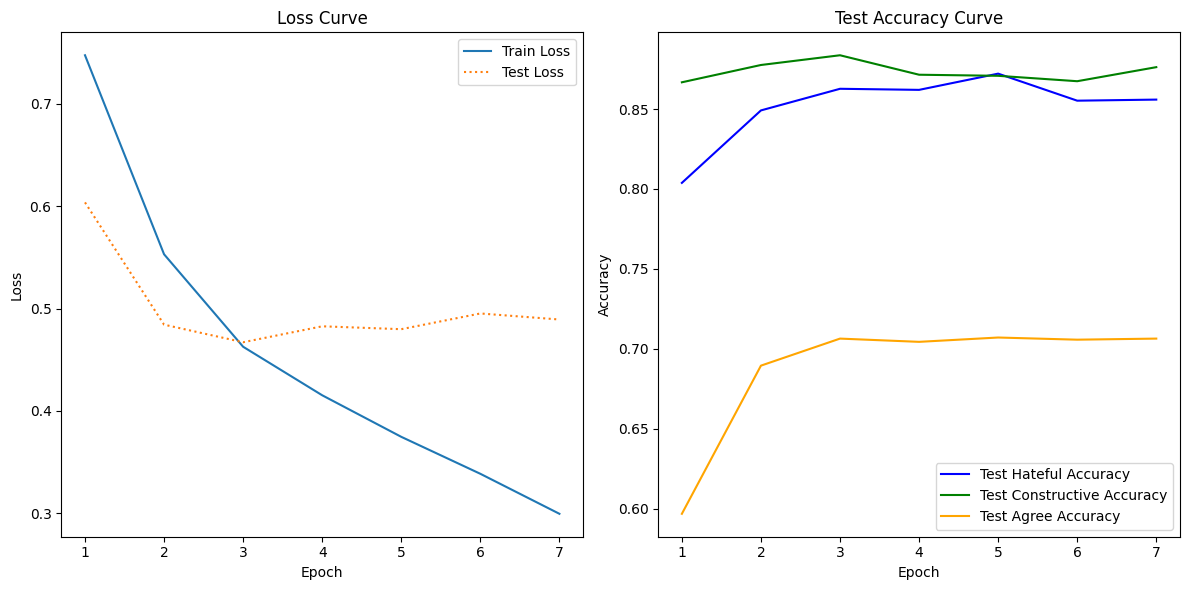

In [3]:
## --- Imports ---

# Data processing 
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
# Modelling 
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import random

'''
Implements a random seed throughout that makes the result replicable. However label smoothing can not be enabled as this messes up the seed
'''

def set_seed(seed):
    # Python's built-in random module
    random.seed(seed)
    
    # Numpy's random module
    np.random.seed(seed)
    
    # PyTorch seed for CPU
    torch.manual_seed(seed)
    
    # PyTorch seed for all GPU devices (if using CUDA)
    torch.cuda.manual_seed_all(seed)
    
    # Make sure to disable CuDNN's non-deterministic optimizations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(1)


'''
The following code will fine-tune a model on a English labeled dataset to predict 1 label for each class where:

class refers to the different ''categories'' of the data. In this case there are 3 classes: 'rep_hateful', 'rep_constructive', 'rep_agree', and 

label refers to the type of each class. In this case there are 9 labels in total, where a text can have only 1 label for each class, e.g. 'Hateful', 'Not Constructive', 'Disagree'. Thus a text cannot have both the labels 'Hateful' and 'Not Hateful'

Explanatory comments are integrated to guide users through the code structure and functionality.
'''

# Set device, run on gpu if available 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")



# Load/prepare data
train_df=eng_dan_data.sample(frac=0.8,random_state=2000) #take 80% of new df
test_df=eng_dan_data.drop(train_df.index) #take new df but to create test but drop the ones that are in train


# Set tokenizer and batch size
tokenizer = AutoTokenizer.from_pretrained('intfloat/multilingual-e5-large')
batch_size = 16


# Map labels to numeric values for each of the classes 
label_mappings = {
    'rep_hateful': {'Not Hateful': 0, 'Hateful': 1, 'Unclassifiable Hateful': 2},
    'rep_constructive': {'Not Constructive': 0, 'Constructive': 1, 'Unclassifiable Constructive': 2},
    'rep_agree': {'Agree': 0, 'Disagree': 1, 'Unclear': 2}}
for column, mapping in label_mappings.items():
    train_df[column] = train_df[column].map(mapping)
    test_df[column] = test_df[column].map(mapping)


# Directly extract the necessary columns as a numpy array (already encoded as 0, 1, 2)
train_labels = train_df[['rep_hateful', 'rep_constructive', 'rep_agree']].astype(int).values
test_labels = test_df[['rep_hateful', 'rep_constructive', 'rep_agree']].astype(int).values



class TextDataset(Dataset):
    def __init__(self, texts, labels_hateful, labels_constructive, labels_agree, tokenizer, max_length = 512):
        self.texts = texts
        self.labels_hateful = labels_hateful
        self.labels_constructive = labels_constructive
        self.labels_agree = labels_agree
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)  # Returns the size of the dataset

    def __getitem__(self, idx):
        text = self.texts[idx]

        # Get labels for each class
        label_hateful = self.labels_hateful[idx]
        label_constructive = self.labels_constructive[idx]
        label_agree = self.labels_agree[idx]

        # Tokenize the text
        encodings = self.tokenizer(
            text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encodings["input_ids"].squeeze(0),  # Squeeze only batch dimension
            "attention_mask": encodings["attention_mask"].squeeze(0),
            "labels_hateful": torch.tensor(label_hateful, dtype=torch.long),
            "labels_constructive": torch.tensor(label_constructive, dtype=torch.long),
            "labels_agree": torch.tensor(label_agree, dtype=torch.long),
        }


# Prepare datasets using the TextDataset class we definedd
train_dataset = TextDataset(
    texts = train_df['rep_text'].tolist(),
    labels_hateful = train_labels[:, 0], # Get first column from train_labels array
    labels_constructive = train_labels[:, 1],
    labels_agree = train_labels[:, 2],
    tokenizer = tokenizer)

    
test_dataset = TextDataset(
    texts = test_df['rep_text'].tolist(),
    labels_hateful = test_labels[:, 0], # Get first column from train_labels array
    labels_constructive = test_labels[:, 1],
    labels_agree = test_labels[:, 2],
    tokenizer = tokenizer)


# Create train and test dataloaders
# Dataset stores the texts and their corresponding labels
# DataLoader wraps an iterable around the Dataset to enable easy access to the texts
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = batch_size)


# Set model
model = AutoModelForSequenceClassification.from_pretrained('intfloat/multilingual-e5-large', num_labels = 9)


# Set criterion: CrossEntropyLoss used for multi output classification. This criterion computes the cross entropy loss between input logits and target
#criterion = nn.CrossEntropyLoss(label_smoothing=0.3)
criterion = nn.CrossEntropyLoss()

# Set optimizer, Adam works well for most tasks
optimizer = optim.AdamW(model.parameters(), lr = 2e-6, weight_decay=1e-1) 
# Define learning rete scheduler 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5, min_lr=1e-7)


# Define training process. The model is set up as a multi-output classification task where each label is independently predicted
def train(model, dataloader, criterion, optimizer, device):
    model.train() # Set to train mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0 # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class
    
    for batch in tqdm(dataloader, desc = "Training"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        
        labels_hateful = batch["labels_hateful"].to(device).long()
        labels_constructive = batch["labels_constructive"].to(device).long()
        labels_agree = batch["labels_agree"].to(device).long()
        
        # Clear out the gradients of all parameters that the optimizer is tracking
        optimizer.zero_grad()
        # Calls the forward pass of the model and processes the input data through the layers of the model
        outputs = model(input_ids, attention_mask = attention_mask)
        
        # Extract logits (raw predictions before applying any activation function)
        # Logits will have a shape of [batch_size, 9] since num_labels = 9
        logits = outputs.logits 

        # Now fetch the logits for each label
        # Split the logits into 3 sets of logits (each corresponding to 1 task with 3 labels)
        logits_hateful = logits[:, :3]           # First 3 logits for the "hateful" task
        logits_constructive = logits[:, 3:6]     # Next 3 logits for the "constructive" task
        logits_agree = logits[:, 6:]             # Last 3 logits for the "agree" task

        # Calculate the loss for each class
        # The criterion (CrossEntropyLoss) applies the softmax function internally to the logits. This transforms the raw logits into probabilities that sum to 1 for each example in the batch. 
        # It then calculates the negative log-likelihood loss based on the true labels
        loss_hateful = criterion(logits_hateful, labels_hateful)
        loss_constructive = criterion(logits_constructive, labels_constructive)
        loss_agree = criterion(logits_agree, labels_agree)

        # Combine the losses (average them)
        loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
        
        # Accumulate the loss as a Python float
        total_loss += loss.item()
        
        # Backward pass and optimizer step
        loss.backward()
        optimizer.step() # Makes the optimizer iterate over all parameters (tensors) it is supposed to update and use their internally stored gradients to update their values.

        # Accuracy calculations
        # Predicts the labels for each task by selecting the label with the highest score (logit)
        preds_hateful = torch.argmax(logits_hateful, dim = 1)
        preds_constructive = torch.argmax(logits_constructive, dim = 1)
        preds_agree = torch.argmax(logits_agree, dim = 1)

        # Calculates how many of the predicted labels are correct and then adds that number to the correct_x counter
        correct_hateful += (preds_hateful == labels_hateful).sum().item()
        correct_constructive += (preds_constructive == labels_constructive).sum().item()
        correct_agree += (preds_agree == labels_agree).sum().item()

        # Keeps track of the total number of texts for each classification task
        total_hateful += labels_hateful.size(0) 
        total_constructive += labels_constructive.size(0)
        total_agree += labels_agree.size(0)

    # Calculate average loss for the train data
    avg_loss_train = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return avg_loss_train, accuracy_hateful, accuracy_constructive, accuracy_agree

    
# Define evaluation process
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set to evaluation mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0  # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class

    # Initalize empty list to store predicted labels and true labels
    # These will be used in making the classfication reports
    all_preds_hateful, all_preds_constructive, all_preds_agree = [],[],[]
    all_labels_hateful, all_labels_constructive, all_labels_agree = [],[],[]

    with torch.no_grad(): # Temporarily disable gradient calculations during the forward pass
        # Saves memory and computation because the operations don't need to be tracked for backward propagation.
        # This is crucial during evaluation (inference) because we don't need to update the model parameters—just forward pass predictions.
        for batch in tqdm(dataloader, desc = "Evaluating"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels_hateful = batch["labels_hateful"].to(device)
            labels_constructive = batch["labels_constructive"].to(device)
            labels_agree = batch["labels_agree"].to(device)

            # Calls the forward pass of the model and processes the input data through the layers of the model
            outputs = model(input_ids, attention_mask = attention_mask)
            # Extract logits
            logits = outputs.logits

            # Split the logits for each task
            logits_hateful = logits[:, :3]          
            logits_constructive = logits[:, 3:6] 
            logits_agree = logits[:, 6:]

            # Calculate loss for each task
            loss_hateful = criterion(logits_hateful, labels_hateful)
            loss_constructive = criterion(logits_constructive, labels_constructive)
            loss_agree = criterion(logits_agree, labels_agree)

            # Combine the losses (average them) and store as float
            loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
            total_loss += loss.item()

            # Predicts the labels for each task
            preds_hateful = torch.argmax(logits_hateful, dim=1).cpu().numpy()
            preds_constructive = torch.argmax(logits_constructive, dim=1).cpu().numpy()
            preds_agree = torch.argmax(logits_agree, dim=1).cpu().numpy()

            # Extend the predictions and true labels
            all_preds_hateful.extend(preds_hateful)
            all_preds_constructive.extend(preds_constructive)
            all_preds_agree.extend(preds_agree)

            all_labels_hateful.extend(labels_hateful.cpu().numpy()) # Use labels on CPU for comparison after moving them to device
            all_labels_constructive.extend(labels_constructive.cpu().numpy())
            all_labels_agree.extend(labels_agree.cpu().numpy())

            # Update counts for correctly predicted labels 
            correct_hateful += (preds_hateful == labels_hateful.cpu().numpy()).sum()
            correct_constructive += (preds_constructive == labels_constructive.cpu().numpy()).sum()
            correct_agree += (preds_agree == labels_agree.cpu().numpy()).sum()

            # Update counts for total number of labels for each class 
            total_hateful += labels_hateful.size(0)
            total_constructive += labels_constructive.size(0)
            total_agree += labels_agree.size(0)

    # Calculate average loss for the test data
    avg_loss_test = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return (avg_loss_test, 
            np.array(all_labels_hateful), np.array(all_preds_hateful),
            np.array(all_labels_constructive), np.array(all_preds_constructive),
            np.array(all_labels_agree), np.array(all_preds_agree),
            accuracy_hateful, accuracy_constructive, accuracy_agree)



# --- Setup saving parameters ---
output_dir = "/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/e5/model_without_ref/"


## --- Running model ---

# Define the label classes
label_classes = { 
    'rep_hateful': ['Not Hateful', 'Hateful', 'Unclassifiable Hateful'],
    'rep_constructive': ['Not Constructive', 'Constructive', 'Unclassifiable Constructive'],
    'rep_agree': ['Agree', 'Disagree', 'Unclear']
}

train_losses, test_losses = [], [] # Empty lists for storing losses
train_accuracies, test_accuracies = [], [] # Empty lists for storing accuracies


# Number of epochs
num_epochs = 20
# Initialize counter for epoch number
epoch_no = 0 
# Empty lists for storing learning rates
lr_history = []
# Counter to track epochs with no improvement
early_stopping_counter = 0  
# Set best_loss to infinitely high to ensure that the first loss will always be lower
best_loss = float('inf')  

# Initialize best accuracy and best loss
best_avg_accuracy = 0.0
best_model_so_far = None 


for epoch in range(num_epochs):
    epoch_no = epoch + 1
    print(f"Epoch {epoch_no}:")

    # Append and print current learning rate
    lr_history.append(scheduler.get_last_lr()[0])
    print(f"Being trained with a learning rate of {lr_history[-1]}")

    # -- Train model -- 
    avg_loss_train, train_acc_hateful, train_acc_constructive, train_acc_agree = train(model, train_dataloader, criterion, optimizer, device)
    train_losses.append(avg_loss_train) # Store training loss
    train_accuracies.append((train_acc_hateful, train_acc_constructive, train_acc_agree)) # Store accuracies for training
    
    # -- Test model -- 
    avg_loss_test, test_true_labels_hateful, test_pred_labels_hateful,test_true_labels_constructive, test_pred_labels_constructive, test_true_labels_agree, test_pred_labels_agree, test_acc_hateful, test_acc_constructive, test_acc_agree =  evaluate(model, test_dataloader, criterion, device)
    test_losses.append(avg_loss_test) # Store test loss
    test_accuracies.append((test_acc_hateful, test_acc_constructive, test_acc_agree)) # Store accuracies for testing

    # Update learning rate with scheduler
    scheduler.step(avg_loss_test)

    # Save accuracy
    avg_accuracy = round((test_acc_hateful+test_acc_constructive + test_acc_agree)/3,3)
    
    # Print results 
    print(f"  Train Loss: {avg_loss_train:.4f}, test Loss: {avg_loss_test:.4f}")
    print(f"  Hateful Accuracy: {test_acc_hateful:.4f}, Constructive Accuracy: {test_acc_constructive:.4f}, Agree Accuracy: {test_acc_agree:.4f}")
    print(f"  Average Accuracy: {avg_accuracy:.4f}")


    # Save the model if it achieves the best average accuracy and stop running if accuracy has not improved 
    if avg_accuracy > best_avg_accuracy:
        best_avg_accuracy = avg_accuracy
        best_model_epoch = epoch_no 

        # Save true and predicted labels for the best model
        best_labels = {
            "hateful": {"true": test_true_labels_hateful, "pred": test_pred_labels_hateful},
            "constructive": {"true": test_true_labels_constructive, "pred": test_pred_labels_constructive},
            "agree": {"true": test_true_labels_agree, "pred": test_pred_labels_agree}
        }
        
        best_model_so_far = model.state_dict()
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1  # Increment the counter if no improvement
        if early_stopping_counter >= 4:
            print("Stopping because early stopping has been triggered.")
            break  # Stop training if patience is exceeded


# Save only the 1 best model off all when all epochs are done
checkpoint_filename = "model_epoch_{epoch}.pt"
best_model_path = output_dir + checkpoint_filename.format(epoch = best_model_epoch)
torch.save(best_model_so_far, best_model_path)


# --- Plotting results ---

# Generate confusion matrix for each class for the best model
for class_name, labels in label_classes.items():

    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Compute the confusion matrix 
        matrix = confusion_matrix(class_true, class_pred)
        # Plot and save the confusion matrix
        plt.figure(figsize = (10,10))
        sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels,
                    yticklabels=labels)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Confusion Matrix for {class_name}_')
        plt.savefig(f'{output_dir}/confusion_matrix_{class_name}_epoch_{best_model_epoch}.png')
        plt.close()


# Generate classification report for each class for the best model
for class_name, labels in label_classes.items():
    
    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Generate classification report as a dictionary
        report = classification_report(class_true, 
                                    class_pred, 
                                    target_names=labels, 
                                    output_dict=True)
        
        # Save the classification report to a text file
        report_filename = f"{output_dir}/classification_report_{class_name}_epoch_{best_model_epoch}.txt"
        with open(report_filename, "w") as f:
            f.write(classification_report(class_true, class_pred, target_names=labels))


plt.figure(figsize = (12,6))

# Loss and accuracy plot over epochs
# Loss curve
plt.subplot(1,2,1)
plt.plot(np.arange(1, epoch_no+1), train_losses, label = "Train Loss")
plt.plot(np.arange(1, epoch_no+1), test_losses, label = "Test Loss", linestyle = ":")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Accuracy on test set (colored by class)
plt.subplot(1, 2, 2)
plt.plot(np.arange(1, epoch_no+1), [x[0] for x in test_accuracies], label = "Test Hateful Accuracy", color = "blue")
plt.plot(np.arange(1, epoch_no+1), [x[1] for x in test_accuracies], label = "Test Constructive Accuracy", color = "green")
plt.plot(np.arange(1, epoch_no+1), [x[2] for x in test_accuracies], label = "Test Agree Accuracy", color = "orange")
plt.title("Test Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Save and show 
plt.savefig(output_dir+f'accuracy_and_loss_curce_plot_epoch_{best_model_epoch}.png')
plt.tight_layout()
plt.show()



##### With ref

Loading weights: 100%|██████████| 389/389 [00:00<00:00, 14339.44it/s]
XLMRobertaForSequenceClassification LOAD REPORT from: intfloat/multilingual-e5-large
Key                        | Status     | 
---------------------------+------------+-
embeddings.position_ids    | UNEXPECTED | 
pooler.dense.bias          | UNEXPECTED | 
pooler.dense.weight        | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  8.90it/s]


  Train Loss: 0.7903, test Loss: 0.6863
  Hateful Accuracy: 0.7788, Constructive Accuracy: 0.8349, Agree Accuracy: 0.5480
  Average Accuracy: 0.7210
Epoch 2:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  8.97it/s]


  Train Loss: 0.6376, test Loss: 0.5475
  Hateful Accuracy: 0.8173, Constructive Accuracy: 0.8620, Agree Accuracy: 0.6752
  Average Accuracy: 0.7850
Epoch 3:
Being trained with a learning rate of 2e-06


... (14 outputs left out)

Evaluating: 100%|██████████| 93/93 [00:10<00:00,  8.97it/s]


  Train Loss: 0.2315, test Loss: 0.5501
  Hateful Accuracy: 0.8613, Constructive Accuracy: 0.8687, Agree Accuracy: 0.7057
  Average Accuracy: 0.8120
Epoch 11:
Being trained with a learning rate of 1e-06


Evaluating: 100%|██████████| 93/93 [00:10<00:00,  8.98it/s]


  Train Loss: 0.1926, test Loss: 0.5536
  Hateful Accuracy: 0.8532, Constructive Accuracy: 0.8660, Agree Accuracy: 0.7179
  Average Accuracy: 0.8120
Stopping because early stopping has been triggered.


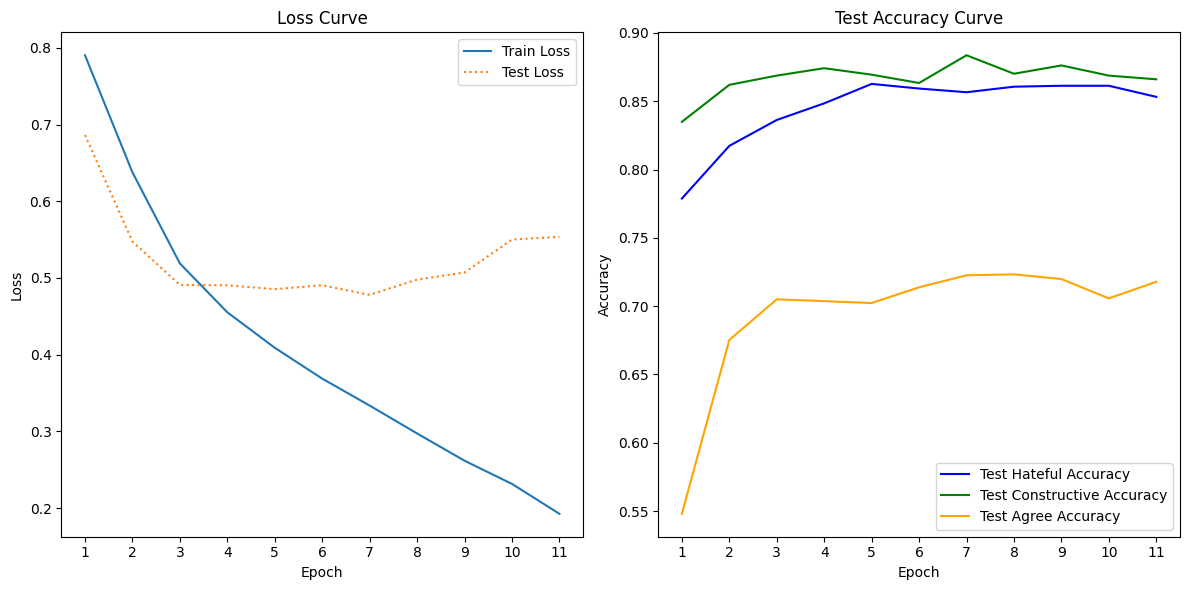

In [4]:
## --- Imports ---

# Data processing 
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
# Modelling 
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import random

'''
Implements a random seed throughout that makes the result replicable. However label smoothing can not be enabled as this messes up the seed
'''

def set_seed(seed):
    # Python's built-in random module
    random.seed(seed)
    
    # Numpy's random module
    np.random.seed(seed)
    
    # PyTorch seed for CPU
    torch.manual_seed(seed)
    
    # PyTorch seed for all GPU devices (if using CUDA)
    torch.cuda.manual_seed_all(seed)
    
    # Make sure to disable CuDNN's non-deterministic optimizations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(1)



'''
The following code will fine-tune a model on a English labeled dataset to predict 1 label for each class where:

class refers to the different ''categories'' of the data. In this case there are 3 classes: 'rep_hateful', 'rep_constructive', 'rep_agree', and 

label refers to the type of each class. In this case there are 9 labels in total, where a text can have only 1 label for each class, e.g. 'Hateful', 'Not Constructive', 'Disagree'. Thus a text cannot have both the labels 'Hateful' and 'Not Hateful'

Explanatory comments are integrated to guide users through the code structure and functionality.
'''

# Set device, run on gpu if available 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Load/prepare data
train_df=eng_dan_data.sample(frac=0.8,random_state=2000) #take 80% of new df
test_df=eng_dan_data.drop(train_df.index) #take new df but to create test but drop the ones that are in train


# Set tokenizer and batch size
tokenizer = AutoTokenizer.from_pretrained("intfloat/multilingual-e5-large")
batch_size = 16


# Map labels to numeric values for each of the classes 
label_mappings = {
    'rep_hateful': {'Not Hateful': 0, 'Hateful': 1, 'Unclassifiable Hateful': 2},
    'rep_constructive': {'Not Constructive': 0, 'Constructive': 1, 'Unclassifiable Constructive': 2},
    'rep_agree': {'Agree': 0, 'Disagree': 1, 'Unclear': 2}}
for column, mapping in label_mappings.items():
    train_df[column] = train_df[column].map(mapping)
    test_df[column] = test_df[column].map(mapping)


# Directly extract the necessary columns as a numpy array (already encoded as 0, 1, 2)
train_labels = train_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values
test_labels = test_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values


# Define class
class TextDataset(Dataset):
    def __init__(self, texts,ref_texts, labels_hateful, labels_constructive, labels_agree, tokenizer, max_length = 512):
        self.texts = texts
        self.ref_texts = ref_texts
        self.labels_hateful = labels_hateful
        self.labels_constructive = labels_constructive
        self.labels_agree = labels_agree
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts) # Returns the size of the dataset

    def __getitem__(self, idx):

        text = self.texts[idx]
        ref_text = self.ref_texts[idx]

        label_hateful = self.labels_hateful[idx]
        label_constructive = self.labels_constructive[idx]
        label_agree = self.labels_agree[idx]

        #the tokenizer automatically inserts the separator tokens
        encodings = self.tokenizer(
            ref_text,
            text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encodings["input_ids"].squeeze(),
            "attention_mask": encodings["attention_mask"].squeeze(),
            "labels_hateful": torch.tensor(label_hateful, dtype=torch.long),
            "labels_constructive": torch.tensor(label_constructive, dtype=torch.long),
            "labels_agree": torch.tensor(label_agree, dtype=torch.long),
        }


# Prepare datasets using the TextDataset class we definedd
train_dataset = TextDataset(
    texts = train_df['rep_text'].tolist(),
    ref_texts = train_df['ref_text'].tolist(),
    labels_hateful = train_labels[:, 0], # Get first column from train_labels array
    labels_constructive = train_labels[:, 1],
    labels_agree = train_labels[:, 2],
    tokenizer = tokenizer)

test_dataset = TextDataset(
    texts = test_df['rep_text'].tolist(),
    ref_texts = test_df['ref_text'].tolist(),
    labels_hateful = test_labels[:, 0], # Get first column from train_labels array
    labels_constructive = test_labels[:, 1],
    labels_agree = test_labels[:, 2],
    tokenizer = tokenizer)


# Create train and test dataloaders
# Dataset stores the texts and their corresponding labels
# DataLoader wraps an iterable around the Dataset to enable easy access to the texts
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = batch_size)


# Set model
model = AutoModelForSequenceClassification.from_pretrained("intfloat/multilingual-e5-large", num_labels = 9)

# Set criterion: CrossEntropyLoss used for multi output classification. This criterion computes the cross entropy loss between input logits and target
#criterion = nn.CrossEntropyLoss(label_smoothing=0.3)
criterion = nn.CrossEntropyLoss()

# Set optimizer, Adam works well for most tasks
optimizer = optim.AdamW(model.parameters(), lr = 2e-6, weight_decay=1e-1) 
# Define learning rete scheduler 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5, min_lr=1e-7)


# Define training process. The model is set up as a multi-output classification task where each label is independently predicted
def train(model, dataloader, criterion, optimizer, device):
    model.train() # Set to train mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0 # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class
    
    for batch in tqdm(dataloader, desc = "Training"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels_hateful = batch["labels_hateful"].to(device)
        labels_constructive = batch["labels_constructive"].to(device)
        labels_agree = batch["labels_agree"].to(device)
        
        # Clear out the gradients of all parameters that the optimizer is tracking
        optimizer.zero_grad()
        # Calls the forward pass of the model and processes the input data through the layers of the model
        outputs = model(input_ids, attention_mask = attention_mask)
        
        # Extract logits (raw predictions before applying any activation function)
        # Logits will have a shape of [batch_size, 9] since num_labels = 9
        logits = outputs.logits 

        # Now fetch the logits for each label
        # Split the logits into 3 sets of logits (each corresponding to 1 task with 3 labels)
        logits_hateful = logits[:, :3]           # First 3 logits for the "hateful" task
        logits_constructive = logits[:, 3:6]     # Next 3 logits for the "constructive" task
        logits_agree = logits[:, 6:]             # Last 3 logits for the "agree" task

        # Calculate the loss for each class
        # The criterion (CrossEntropyLoss) applies the softmax function internally to the logits. This transforms the raw logits into probabilities that sum to 1 for each example in the batch. 
        # It then calculates the negative log-likelihood loss based on the true labels
        loss_hateful = criterion(logits_hateful, labels_hateful)
        loss_constructive = criterion(logits_constructive, labels_constructive)
        loss_agree = criterion(logits_agree, labels_agree)

        # Combine the losses (average them)
        loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
        
        # Accumulate the loss as a Python float
        total_loss += loss.item()
        
        # Backward pass and optimizer step
        loss.backward()
        optimizer.step() # Makes the optimizer iterate over all parameters (tensors) it is supposed to update and use their internally stored gradients to update their values.

        # Accuracy calculations
        # Predicts the labels for each task by selecting the label with the highest score (logit)
        preds_hateful = torch.argmax(logits_hateful, dim = 1)
        preds_constructive = torch.argmax(logits_constructive, dim = 1)
        preds_agree = torch.argmax(logits_agree, dim = 1)

        # Calculates how many of the predicted labels are correct and then adds that number to the correct_x counter
        correct_hateful += (preds_hateful == labels_hateful).sum().item()
        correct_constructive += (preds_constructive == labels_constructive).sum().item()
        correct_agree += (preds_agree == labels_agree).sum().item()

        # Keeps track of the total number of texts for each classification task
        total_hateful += labels_hateful.size(0) 
        total_constructive += labels_constructive.size(0)
        total_agree += labels_agree.size(0)

    # Calculate average loss for the train data
    avg_loss_train = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return avg_loss_train, accuracy_hateful, accuracy_constructive, accuracy_agree

    
# Define evaluation process
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set to evaluation mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0  # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class

    # Initalize empty list to store predicted labels and true labels
    # These will be used in making the classfication reports
    all_preds_hateful, all_preds_constructive, all_preds_agree = [],[],[]
    all_labels_hateful, all_labels_constructive, all_labels_agree = [],[],[]

    with torch.no_grad(): # Temporarily disable gradient calculations during the forward pass
        # Saves memory and computation because the operations don't need to be tracked for backward propagation.
        # This is crucial during evaluation (inference) because we don't need to update the model parameters—just forward pass predictions.
        for batch in tqdm(dataloader, desc = "Evaluating"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels_hateful = batch["labels_hateful"].to(device)
            labels_constructive = batch["labels_constructive"].to(device)
            labels_agree = batch["labels_agree"].to(device)

            # Calls the forward pass of the model and processes the input data through the layers of the model
            outputs = model(input_ids, attention_mask = attention_mask)
            # Extract logits
            logits = outputs.logits

            # Split the logits for each task
            logits_hateful = logits[:, :3]          
            logits_constructive = logits[:, 3:6] 
            logits_agree = logits[:, 6:]

            # Calculate loss for each task
            loss_hateful = criterion(logits_hateful, labels_hateful)
            loss_constructive = criterion(logits_constructive, labels_constructive)
            loss_agree = criterion(logits_agree, labels_agree)

            # Combine the losses (average them) and store as float
            loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
            total_loss += loss.item()

            # Predicts the labels for each task
            preds_hateful = torch.argmax(logits_hateful, dim=1).cpu().numpy()
            preds_constructive = torch.argmax(logits_constructive, dim=1).cpu().numpy()
            preds_agree = torch.argmax(logits_agree, dim=1).cpu().numpy()

            # Extend the predictions and true labels
            all_preds_hateful.extend(preds_hateful)
            all_preds_constructive.extend(preds_constructive)
            all_preds_agree.extend(preds_agree)

            all_labels_hateful.extend(labels_hateful.cpu().numpy()) # Use labels on CPU for comparison after moving them to device
            all_labels_constructive.extend(labels_constructive.cpu().numpy())
            all_labels_agree.extend(labels_agree.cpu().numpy())

            # Update counts for correctly predicted labels 
            correct_hateful += (preds_hateful == labels_hateful.cpu().numpy()).sum()
            correct_constructive += (preds_constructive == labels_constructive.cpu().numpy()).sum()
            correct_agree += (preds_agree == labels_agree.cpu().numpy()).sum()

            # Update counts for total number of labels for each class 
            total_hateful += labels_hateful.size(0)
            total_constructive += labels_constructive.size(0)
            total_agree += labels_agree.size(0)

    # Calculate average loss for the test data
    avg_loss_test = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return (avg_loss_test, 
            np.array(all_labels_hateful), np.array(all_preds_hateful),
            np.array(all_labels_constructive), np.array(all_preds_constructive),
            np.array(all_labels_agree), np.array(all_preds_agree),
            accuracy_hateful, accuracy_constructive, accuracy_agree)



# --- Setup saving parameters ---
output_dir = "/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/e5/model_with_ref/"


## --- Running model ---

# Define the label classes
label_classes = { 
    'rep_hateful': ['Not Hateful', 'Hateful', 'Unclassifiable Hateful'],
    'rep_constructive': ['Not Constructive', 'Constructive', 'Unclassifiable Constructive'],
    'rep_agree': ['Agree', 'Disagree', 'Unclear']
}

train_losses, test_losses = [], [] # Empty lists for storing losses
train_accuracies, test_accuracies = [], [] # Empty lists for storing accuracies


# Number of epochs
num_epochs = 20
# Initialize counter for epoch number
epoch_no = 0 
# Empty lists for storing learning rates
lr_history = []
# Counter to track epochs with no improvement
early_stopping_counter = 0  
# Set best_loss to infinitely high to ensure that the first loss will always be lower
best_loss = float('inf')  
# Initialize best accuracy and best loss
best_avg_accuracy = 0.0
best_model_so_far = None 


for epoch in range(num_epochs):
    epoch_no = epoch + 1
    print(f"Epoch {epoch_no}:")

    # Append and print current learning rate
    lr_history.append(scheduler.get_last_lr()[0])
    print(f"Being trained with a learning rate of {lr_history[-1]}")

    # -- Train model -- 
    avg_loss_train, train_acc_hateful, train_acc_constructive, train_acc_agree = train(model, train_dataloader, criterion, optimizer, device)
    train_losses.append(avg_loss_train) # Store training loss
    train_accuracies.append((train_acc_hateful, train_acc_constructive, train_acc_agree)) # Store accuracies for training
    
    # -- Test model -- 
    avg_loss_test, test_true_labels_hateful, test_pred_labels_hateful,test_true_labels_constructive, test_pred_labels_constructive, test_true_labels_agree, test_pred_labels_agree, test_acc_hateful, test_acc_constructive, test_acc_agree =  evaluate(model, test_dataloader, criterion, device)
    test_losses.append(avg_loss_test) # Store test loss
    test_accuracies.append((test_acc_hateful, test_acc_constructive, test_acc_agree)) # Store accuracies for testing

    # Update learning rate with scheduler
    scheduler.step(avg_loss_test)

    # Save accuracy
    avg_accuracy = round((test_acc_hateful+test_acc_constructive + test_acc_agree)/3,3)
    
    # Print results 
    print(f"  Train Loss: {avg_loss_train:.4f}, test Loss: {avg_loss_test:.4f}")
    print(f"  Hateful Accuracy: {test_acc_hateful:.4f}, Constructive Accuracy: {test_acc_constructive:.4f}, Agree Accuracy: {test_acc_agree:.4f}")
    print(f"  Average Accuracy: {avg_accuracy:.4f}")


    # Save the model if it achieves the best average accuracy and stop running if accuracy has not improved 
    if avg_accuracy > best_avg_accuracy:
        best_avg_accuracy = avg_accuracy
        best_model_epoch = epoch_no 

        # Save true and predicted labels for the best model
        best_labels = {
            "hateful": {"true": test_true_labels_hateful, "pred": test_pred_labels_hateful},
            "constructive": {"true": test_true_labels_constructive, "pred": test_pred_labels_constructive},
            "agree": {"true": test_true_labels_agree, "pred": test_pred_labels_agree}
        }
        
        best_model_so_far = model.state_dict()
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1  # Increment the counter if no improvement
        if early_stopping_counter >= 4:
            print("Stopping because early stopping has been triggered.")
            break  # Stop training if patience is exceeded


# Save only the 1 best model off all when all epochs are done
checkpoint_filename = "model_epoch_{epoch}.pt"
best_model_path = output_dir + checkpoint_filename.format(epoch = best_model_epoch)
torch.save(best_model_so_far, best_model_path)


# --- Plotting results ---

# Generate confusion matrix for each class for the best model
for class_name, labels in label_classes.items():

    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Compute the confusion matrix 
        matrix = confusion_matrix(class_true, class_pred)
        # Plot and save the confusion matrix
        plt.figure(figsize = (10,10))
        sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels,
                    yticklabels=labels)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Confusion Matrix for {class_name}_')
        plt.savefig(f'{output_dir}/confusion_matrix_{class_name}_epoch_{best_model_epoch}.png')
        plt.close()


# Generate classification report for each class for the best model
for class_name, labels in label_classes.items():
    
    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Generate classification report as a dictionary
        report = classification_report(class_true, 
                                    class_pred, 
                                    target_names=labels, 
                                    output_dict=True)
        
        # Save the classification report to a text file
        report_filename = f"{output_dir}/classification_report_{class_name}_epoch_{best_model_epoch}.txt"
        with open(report_filename, "w") as f:
            f.write(classification_report(class_true, class_pred, target_names=labels))


plt.figure(figsize = (12,6))

# Loss and accuracy plot over epochs
# Loss curve
plt.subplot(1,2,1)
plt.plot(np.arange(1, epoch_no+1), train_losses, label = "Train Loss")
plt.plot(np.arange(1, epoch_no+1), test_losses, label = "Test Loss", linestyle = ":")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Accuracy on test set (colored by class)
plt.subplot(1, 2, 2)
plt.plot(np.arange(1, epoch_no+1), [x[0] for x in test_accuracies], label = "Test Hateful Accuracy", color = "blue")
plt.plot(np.arange(1, epoch_no+1), [x[1] for x in test_accuracies], label = "Test Constructive Accuracy", color = "green")
plt.plot(np.arange(1, epoch_no+1), [x[2] for x in test_accuracies], label = "Test Agree Accuracy", color = "orange")
plt.title("Test Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Save and show 
plt.savefig(output_dir+f'accuracy_and_loss_curce_plot_epoch_{best_model_epoch}.png')
plt.tight_layout()
plt.show()




#### mmBERT-base

- https://huggingface.co/jhu-clsp/mmBERT-base
- Multilingual
- 0.3B params
- Fill-mask type
- Encoder-only

##### Without ref

Loading weights: 100%|██████████| 136/136 [00:00<00:00, 69879.38it/s]
ModernBertForSequenceClassification LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     | 
------------------+------------+-
decoder.weight    | UNEXPECTED | 
decoder.bias      | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:04<00:00, 19.43it/s]


  Train Loss: 0.7363, test Loss: 0.6012
  Hateful Accuracy: 0.8146, Constructive Accuracy: 0.8620, Agree Accuracy: 0.5744
  Average Accuracy: 0.7500
Epoch 2:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:04<00:00, 19.42it/s]


  Train Loss: 0.5661, test Loss: 0.5644
  Hateful Accuracy: 0.8309, Constructive Accuracy: 0.8566, Agree Accuracy: 0.6184
  Average Accuracy: 0.7690
Epoch 3:
Being trained with a learning rate of 2e-06


... (10 outputs left out)

Evaluating: 100%|██████████| 93/93 [00:04<00:00, 19.42it/s]


  Train Loss: 0.1303, test Loss: 0.7702
  Hateful Accuracy: 0.8153, Constructive Accuracy: 0.8383, Agree Accuracy: 0.6461
  Average Accuracy: 0.7670
Epoch 9:
Being trained with a learning rate of 1e-06


Evaluating: 100%|██████████| 93/93 [00:04<00:00, 19.38it/s]


  Train Loss: 0.0901, test Loss: 0.8318
  Hateful Accuracy: 0.8119, Constructive Accuracy: 0.8329, Agree Accuracy: 0.6407
  Average Accuracy: 0.7620
Stopping because early stopping has been triggered.


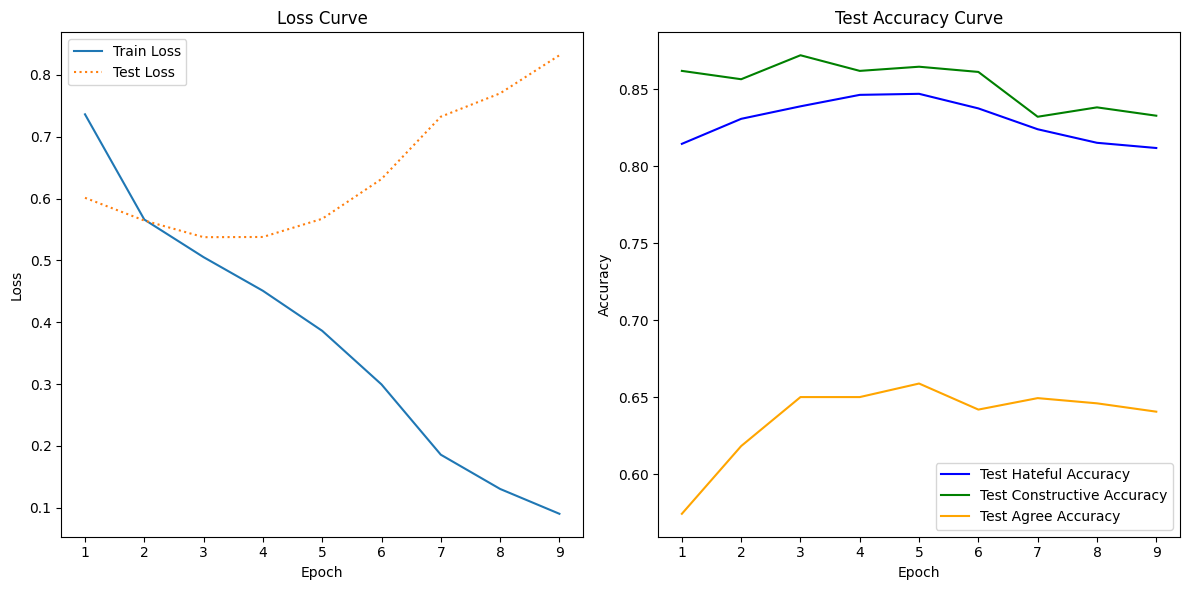

In [5]:
## --- Imports ---

# Data processing 
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
# Modelling 
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import random

'''
Implements a random seed throughout that makes the result replicable. However label smoothing can not be enabled as this messes up the seed
'''

def set_seed(seed):
    # Python's built-in random module
    random.seed(seed)
    
    # Numpy's random module
    np.random.seed(seed)
    
    # PyTorch seed for CPU
    torch.manual_seed(seed)
    
    # PyTorch seed for all GPU devices (if using CUDA)
    torch.cuda.manual_seed_all(seed)
    
    # Make sure to disable CuDNN's non-deterministic optimizations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(1)



'''
The following code will fine-tune a model on a English labeled dataset to predict 1 label for each class where:

class refers to the different ''categories'' of the data. In this case there are 3 classes: 'rep_hateful', 'rep_constructive', 'rep_agree', and 

label refers to the type of each class. In this case there are 9 labels in total, where a text can have only 1 label for each class, e.g. 'Hateful', 'Not Constructive', 'Disagree'. Thus a text cannot have both the labels 'Hateful' and 'Not Hateful'

Explanatory comments are integrated to guide users through the code structure and functionality.
'''

# Set device, run on gpu if available 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load/prepare data
train_df=eng_dan_data.sample(frac=0.8,random_state=2000) #take 80% of new df
test_df=eng_dan_data.drop(train_df.index) #take new df but to create test but drop the ones that are in train


# Set tokenizer and batch size
tokenizer = AutoTokenizer.from_pretrained("jhu-clsp/mmBERT-base")
batch_size = 16


# Map labels to numeric values for each of the classes 
label_mappings = {
    'rep_hateful': {'Not Hateful': 0, 'Hateful': 1, 'Unclassifiable Hateful': 2},
    'rep_constructive': {'Not Constructive': 0, 'Constructive': 1, 'Unclassifiable Constructive': 2},
    'rep_agree': {'Agree': 0, 'Disagree': 1, 'Unclear': 2}}
for column, mapping in label_mappings.items():
    train_df[column] = train_df[column].map(mapping)
    test_df[column] = test_df[column].map(mapping)


# Directly extract the necessary columns as a numpy array (already encoded as 0, 1, 2)
train_labels = train_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values
test_labels = test_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values


# Define class
class TextDataset(Dataset):
    def __init__(self, texts, labels_hateful, labels_constructive, labels_agree, tokenizer, max_length = 512):
        self.texts = texts
        self.labels_hateful = labels_hateful
        self.labels_constructive = labels_constructive
        self.labels_agree = labels_agree
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts) # Returns the size of the dataset

    def __getitem__(self, idx):
        text = self.texts[idx]
        # Get labels for each class
        label_hateful = self.labels_hateful[idx]
        label_constructive = self.labels_constructive[idx]
        label_agree = self.labels_agree[idx]

        # Tokenize the text
        encodings = self.tokenizer(
            text,
            padding = "max_length",
            truncation = True,
            max_length = self.max_length,
            return_tensors = "pt")

        # Return input tensors and labels for each class
        return {
            "input_ids": encodings["input_ids"].squeeze(),  # Squeeze function converts to the correct shape
            "attention_mask": encodings["attention_mask"].squeeze(),
            "labels_hateful": torch.tensor(label_hateful, dtype = torch.long), # Convert labels into tensor format
            "labels_constructive": torch.tensor(label_constructive, dtype = torch.long), # Long function to get 64-bit integer numbers 
            "labels_agree": torch.tensor(label_agree, dtype = torch.long)}


# Prepare datasets using the TextDataset class we definedd
train_dataset = TextDataset(
    texts = train_df['rep_text'].tolist(),
    labels_hateful = train_labels[:, 0], # Get first column from train_labels array
    labels_constructive = train_labels[:, 1],
    labels_agree = train_labels[:, 2],
    tokenizer = tokenizer)

test_dataset = TextDataset(
    texts = test_df['rep_text'].tolist(),
    labels_hateful = test_labels[:, 0], # Get first column from train_labels array
    labels_constructive = test_labels[:, 1],
    labels_agree = test_labels[:, 2],
    tokenizer = tokenizer)


# Create train and test dataloaders
# Dataset stores the texts and their corresponding labels
# DataLoader wraps an iterable around the Dataset to enable easy access to the texts
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = batch_size)


# Set model
model = AutoModelForSequenceClassification.from_pretrained("jhu-clsp/mmBERT-base", num_labels = 9)

# Set criterion: CrossEntropyLoss used for multi output classification. This criterion computes the cross entropy loss between input logits and target
#criterion = nn.CrossEntropyLoss(label_smoothing=0.3)
criterion = nn.CrossEntropyLoss()

# Set optimizer, Adam works well for most tasks
optimizer = optim.AdamW(model.parameters(), lr = 2e-6, weight_decay=1e-1) 

# Define learning rete scheduler 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5, min_lr=1e-7)


# Define training process. The model is set up as a multi-output classification task where each label is independently predicted
def train(model, dataloader, criterion, optimizer, device):
    model.train() # Set to train mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0 # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class
    
    for batch in tqdm(dataloader, desc = "Training"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels_hateful = batch["labels_hateful"].to(device)
        labels_constructive = batch["labels_constructive"].to(device)
        labels_agree = batch["labels_agree"].to(device)
        
        # Clear out the gradients of all parameters that the optimizer is tracking
        optimizer.zero_grad()
        # Calls the forward pass of the model and processes the input data through the layers of the model
        outputs = model(input_ids, attention_mask = attention_mask)
        
        # Extract logits (raw predictions before applying any activation function)
        # Logits will have a shape of [batch_size, 9] since num_labels = 9
        logits = outputs.logits 

        # Now fetch the logits for each label
        # Split the logits into 3 sets of logits (each corresponding to 1 task with 3 labels)
        logits_hateful = logits[:, :3]           # First 3 logits for the "hateful" task
        logits_constructive = logits[:, 3:6]     # Next 3 logits for the "constructive" task
        logits_agree = logits[:, 6:]             # Last 3 logits for the "agree" task

        # Calculate the loss for each class
        # The criterion (CrossEntropyLoss) applies the softmax function internally to the logits. This transforms the raw logits into probabilities that sum to 1 for each example in the batch. 
        # It then calculates the negative log-likelihood loss based on the true labels
        loss_hateful = criterion(logits_hateful, labels_hateful)
        loss_constructive = criterion(logits_constructive, labels_constructive)
        loss_agree = criterion(logits_agree, labels_agree)

        # Combine the losses (average them)
        loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
        
        # Accumulate the loss as a Python float
        total_loss += loss.item()
        
        # Backward pass and optimizer step
        loss.backward()
        optimizer.step() # Makes the optimizer iterate over all parameters (tensors) it is supposed to update and use their internally stored gradients to update their values.

        # Accuracy calculations
        # Predicts the labels for each task by selecting the label with the highest score (logit)
        preds_hateful = torch.argmax(logits_hateful, dim = 1)
        preds_constructive = torch.argmax(logits_constructive, dim = 1)
        preds_agree = torch.argmax(logits_agree, dim = 1)

        # Calculates how many of the predicted labels are correct and then adds that number to the correct_x counter
        correct_hateful += (preds_hateful == labels_hateful).sum().item()
        correct_constructive += (preds_constructive == labels_constructive).sum().item()
        correct_agree += (preds_agree == labels_agree).sum().item()

        # Keeps track of the total number of texts for each classification task
        total_hateful += labels_hateful.size(0) 
        total_constructive += labels_constructive.size(0)
        total_agree += labels_agree.size(0)

    # Calculate average loss for the train data
    avg_loss_train = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return avg_loss_train, accuracy_hateful, accuracy_constructive, accuracy_agree

    
# Define evaluation process
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set to evaluation mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0  # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class

    # Initalize empty list to store predicted labels and true labels
    # These will be used in making the classfication reports
    all_preds_hateful, all_preds_constructive, all_preds_agree = [],[],[]
    all_labels_hateful, all_labels_constructive, all_labels_agree = [],[],[]

    with torch.no_grad(): # Temporarily disable gradient calculations during the forward pass
        # Saves memory and computation because the operations don't need to be tracked for backward propagation.
        # This is crucial during evaluation (inference) because we don't need to update the model parameters—just forward pass predictions.
        for batch in tqdm(dataloader, desc = "Evaluating"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels_hateful = batch["labels_hateful"].to(device)
            labels_constructive = batch["labels_constructive"].to(device)
            labels_agree = batch["labels_agree"].to(device)

            # Calls the forward pass of the model and processes the input data through the layers of the model
            outputs = model(input_ids, attention_mask = attention_mask)
            # Extract logits
            logits = outputs.logits

            # Split the logits for each task
            logits_hateful = logits[:, :3]          
            logits_constructive = logits[:, 3:6] 
            logits_agree = logits[:, 6:]

            # Calculate loss for each task
            loss_hateful = criterion(logits_hateful, labels_hateful)
            loss_constructive = criterion(logits_constructive, labels_constructive)
            loss_agree = criterion(logits_agree, labels_agree)

            # Combine the losses (average them) and store as float
            loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
            total_loss += loss.item()

            # Predicts the labels for each task
            preds_hateful = torch.argmax(logits_hateful, dim=1).cpu().numpy()
            preds_constructive = torch.argmax(logits_constructive, dim=1).cpu().numpy()
            preds_agree = torch.argmax(logits_agree, dim=1).cpu().numpy()

            # Extend the predictions and true labels
            all_preds_hateful.extend(preds_hateful)
            all_preds_constructive.extend(preds_constructive)
            all_preds_agree.extend(preds_agree)

            all_labels_hateful.extend(labels_hateful.cpu().numpy()) # Use labels on CPU for comparison after moving them to device
            all_labels_constructive.extend(labels_constructive.cpu().numpy())
            all_labels_agree.extend(labels_agree.cpu().numpy())

            # Update counts for correctly predicted labels 
            correct_hateful += (preds_hateful == labels_hateful.cpu().numpy()).sum()
            correct_constructive += (preds_constructive == labels_constructive.cpu().numpy()).sum()
            correct_agree += (preds_agree == labels_agree.cpu().numpy()).sum()

            # Update counts for total number of labels for each class 
            total_hateful += labels_hateful.size(0)
            total_constructive += labels_constructive.size(0)
            total_agree += labels_agree.size(0)

    # Calculate average loss for the test data
    avg_loss_test = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return (avg_loss_test, 
            np.array(all_labels_hateful), np.array(all_preds_hateful),
            np.array(all_labels_constructive), np.array(all_preds_constructive),
            np.array(all_labels_agree), np.array(all_preds_agree),
            accuracy_hateful, accuracy_constructive, accuracy_agree)



# --- Setup saving parameters ---
output_dir = "/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/mmbert/model_without_ref/"


## --- Running model ---

# Define the label classes
label_classes = { 
    'rep_hateful': ['Not Hateful', 'Hateful', 'Unclassifiable Hateful'],
    'rep_constructive': ['Not Constructive', 'Constructive', 'Unclassifiable Constructive'],
    'rep_agree': ['Agree', 'Disagree', 'Unclear']
}

train_losses, test_losses = [], [] # Empty lists for storing losses
train_accuracies, test_accuracies = [], [] # Empty lists for storing accuracies


# Number of epochs
num_epochs = 20
# Initialize counter for epoch number
epoch_no = 0 
# Empty lists for storing learning rates
lr_history = []
# Counter to track epochs with no improvement
early_stopping_counter = 0  
# Set best_loss to infinitely high to ensure that the first loss will always be lower
best_loss = float('inf')  
# Initialize best accuracy and best loss
best_avg_accuracy = 0.0
best_model_so_far = None 


for epoch in range(num_epochs):
    epoch_no = epoch + 1
    print(f"Epoch {epoch_no}:")

    # Append and print current learning rate
    lr_history.append(scheduler.get_last_lr()[0])
    print(f"Being trained with a learning rate of {lr_history[-1]}")

    # -- Train model -- 
    avg_loss_train, train_acc_hateful, train_acc_constructive, train_acc_agree = train(model, train_dataloader, criterion, optimizer, device)
    train_losses.append(avg_loss_train) # Store training loss
    train_accuracies.append((train_acc_hateful, train_acc_constructive, train_acc_agree)) # Store accuracies for training
    
    # -- Test model -- 
    avg_loss_test, test_true_labels_hateful, test_pred_labels_hateful,test_true_labels_constructive, test_pred_labels_constructive, test_true_labels_agree, test_pred_labels_agree, test_acc_hateful, test_acc_constructive, test_acc_agree =  evaluate(model, test_dataloader, criterion, device)
    test_losses.append(avg_loss_test) # Store test loss
    test_accuracies.append((test_acc_hateful, test_acc_constructive, test_acc_agree)) # Store accuracies for testing

    # Update learning rate with scheduler
    scheduler.step(avg_loss_test)

    # Save accuracy
    avg_accuracy = round((test_acc_hateful+test_acc_constructive + test_acc_agree)/3,3)
    
    # Print results 
    print(f"  Train Loss: {avg_loss_train:.4f}, test Loss: {avg_loss_test:.4f}")
    print(f"  Hateful Accuracy: {test_acc_hateful:.4f}, Constructive Accuracy: {test_acc_constructive:.4f}, Agree Accuracy: {test_acc_agree:.4f}")
    print(f"  Average Accuracy: {avg_accuracy:.4f}")


    # Save the model if it achieves the best average accuracy and stop running if accuracy has not improved 
    if avg_accuracy > best_avg_accuracy:
        best_avg_accuracy = avg_accuracy
        best_model_epoch = epoch_no 

        # Save true and predicted labels for the best model
        best_labels = {
            "hateful": {"true": test_true_labels_hateful, "pred": test_pred_labels_hateful},
            "constructive": {"true": test_true_labels_constructive, "pred": test_pred_labels_constructive},
            "agree": {"true": test_true_labels_agree, "pred": test_pred_labels_agree}
        }
        
        best_model_so_far = model.state_dict()
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1  # Increment the counter if no improvement
        if early_stopping_counter >= 4:
            print("Stopping because early stopping has been triggered.")
            break  # Stop training if patience is exceeded


# Save only the 1 best model off all when all epochs are done
checkpoint_filename = "model_epoch_{epoch}.pt"
best_model_path = output_dir + checkpoint_filename.format(epoch = best_model_epoch)
torch.save(best_model_so_far, best_model_path)


# --- Plotting results ---

# Generate confusion matrix for each class for the best model
for class_name, labels in label_classes.items():

    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Compute the confusion matrix 
        matrix = confusion_matrix(class_true, class_pred)
        # Plot and save the confusion matrix
        plt.figure(figsize = (10,10))
        sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels,
                    yticklabels=labels)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Confusion Matrix for {class_name}_')
        plt.savefig(f'{output_dir}/confusion_matrix_{class_name}_epoch_{best_model_epoch}.png')
        plt.close()


# Generate classification report for each class for the best model
for class_name, labels in label_classes.items():
    
    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Generate classification report as a dictionary
        report = classification_report(class_true, 
                                    class_pred, 
                                    target_names=labels, 
                                    output_dict=True)
        
        # Save the classification report to a text file
        report_filename = f"{output_dir}/classification_report_{class_name}_epoch_{best_model_epoch}.txt"
        with open(report_filename, "w") as f:
            f.write(classification_report(class_true, class_pred, target_names=labels))


plt.figure(figsize = (12,6))

# Loss and accuracy plot over epochs
# Loss curve
plt.subplot(1,2,1)
plt.plot(np.arange(1, epoch_no+1), train_losses, label = "Train Loss")
plt.plot(np.arange(1, epoch_no+1), test_losses, label = "Test Loss", linestyle = ":")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Accuracy on test set (colored by class)
plt.subplot(1, 2, 2)
plt.plot(np.arange(1, epoch_no+1), [x[0] for x in test_accuracies], label = "Test Hateful Accuracy", color = "blue")
plt.plot(np.arange(1, epoch_no+1), [x[1] for x in test_accuracies], label = "Test Constructive Accuracy", color = "green")
plt.plot(np.arange(1, epoch_no+1), [x[2] for x in test_accuracies], label = "Test Agree Accuracy", color = "orange")
plt.title("Test Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Save and show 
plt.savefig(output_dir+f'accuracy_and_loss_curce_plot_epoch_{best_model_epoch}.png')
plt.tight_layout()
plt.show()



##### With ref

Loading weights: 100%|██████████| 136/136 [00:00<00:00, 77314.36it/s]
ModernBertForSequenceClassification LOAD REPORT from: jhu-clsp/mmBERT-base
Key               | Status     | 
------------------+------------+-
decoder.weight    | UNEXPECTED | 
decoder.bias      | UNEXPECTED | 
classifier.weight | MISSING    | 
classifier.bias   | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:04<00:00, 19.07it/s]


  Train Loss: 0.8008, test Loss: 0.6744
  Hateful Accuracy: 0.7855, Constructive Accuracy: 0.8288, Agree Accuracy: 0.5717
  Average Accuracy: 0.7290
Epoch 2:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:04<00:00, 19.12it/s]


  Train Loss: 0.6373, test Loss: 0.6221
  Hateful Accuracy: 0.7889, Constructive Accuracy: 0.8302, Agree Accuracy: 0.6130
  Average Accuracy: 0.7440
Epoch 3:
Being trained with a learning rate of 2e-06


... (8 outputs left out)

Evaluating: 100%|██████████| 93/93 [00:04<00:00, 19.11it/s]


  Train Loss: 0.2443, test Loss: 0.6537
  Hateful Accuracy: 0.7991, Constructive Accuracy: 0.8457, Agree Accuracy: 0.6583
  Average Accuracy: 0.7680
Epoch 8:
Being trained with a learning rate of 1e-06


Evaluating: 100%|██████████| 93/93 [00:04<00:00, 19.08it/s]


  Train Loss: 0.1321, test Loss: 0.7119
  Hateful Accuracy: 0.8119, Constructive Accuracy: 0.8505, Agree Accuracy: 0.6610
  Average Accuracy: 0.7740
Stopping because early stopping has been triggered.


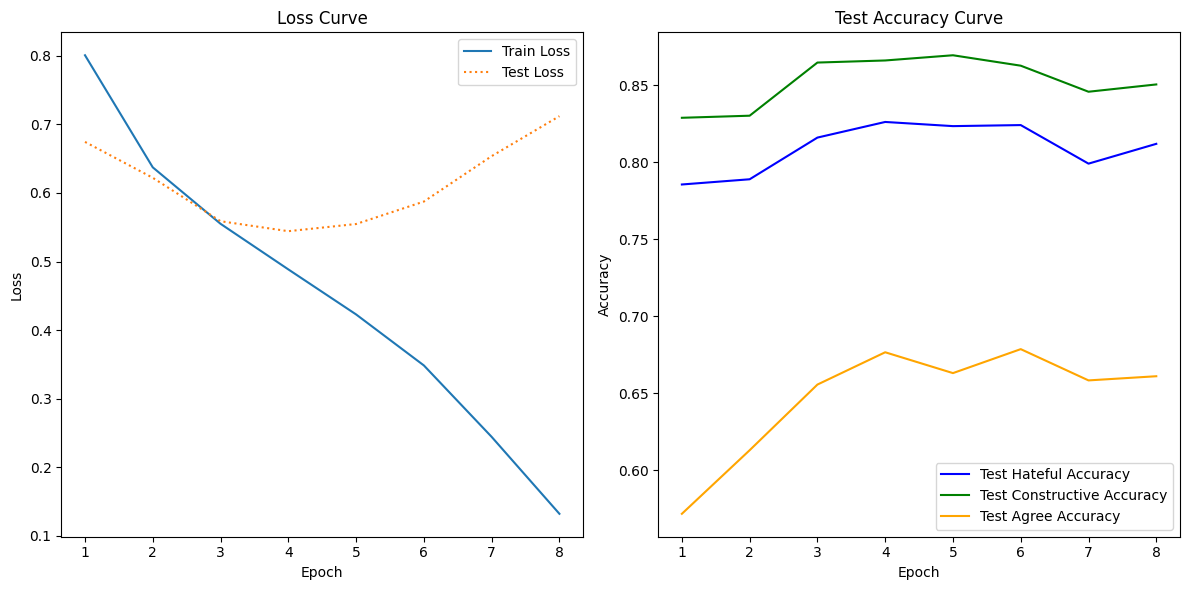

In [6]:
## --- Imports ---

# Data processing 
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
# Modelling 
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import random

'''
Implements a random seed throughout that makes the result replicable. However label smoothing can not be enabled as this messes up the seed
'''

def set_seed(seed):
    # Python's built-in random module
    random.seed(seed)
    
    # Numpy's random module
    np.random.seed(seed)
    
    # PyTorch seed for CPU
    torch.manual_seed(seed)
    
    # PyTorch seed for all GPU devices (if using CUDA)
    torch.cuda.manual_seed_all(seed)
    
    # Make sure to disable CuDNN's non-deterministic optimizations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(1)



'''
The following code will fine-tune a model on a English labeled dataset to predict 1 label for each class where:

class refers to the different ''categories'' of the data. In this case there are 3 classes: 'rep_hateful', 'rep_constructive', 'rep_agree', and 

label refers to the type of each class. In this case there are 9 labels in total, where a text can have only 1 label for each class, e.g. 'Hateful', 'Not Constructive', 'Disagree'. Thus a text cannot have both the labels 'Hateful' and 'Not Hateful'

Explanatory comments are integrated to guide users through the code structure and functionality.
'''

# Set device, run on gpu if available 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load/prepare data
train_df=eng_dan_data.sample(frac=0.8,random_state=2000) #take 80% of new df
test_df=eng_dan_data.drop(train_df.index) #take new df but to create test but drop the ones that are in train


# Set tokenizer and batch size
tokenizer = AutoTokenizer.from_pretrained("jhu-clsp/mmBERT-base")
batch_size = 16


# Map labels to numeric values for each of the classes 
label_mappings = {
    'rep_hateful': {'Not Hateful': 0, 'Hateful': 1, 'Unclassifiable Hateful': 2},
    'rep_constructive': {'Not Constructive': 0, 'Constructive': 1, 'Unclassifiable Constructive': 2},
    'rep_agree': {'Agree': 0, 'Disagree': 1, 'Unclear': 2}}
for column, mapping in label_mappings.items():
    train_df[column] = train_df[column].map(mapping)
    test_df[column] = test_df[column].map(mapping)


# Directly extract the necessary columns as a numpy array (already encoded as 0, 1, 2)
train_labels = train_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values
test_labels = test_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values


# Define class
class TextDataset(Dataset):
    def __init__(self, texts,ref_texts, labels_hateful, labels_constructive, labels_agree, tokenizer, max_length = 512):
        self.texts = texts
        self.ref_texts = ref_texts
        self.labels_hateful = labels_hateful
        self.labels_constructive = labels_constructive
        self.labels_agree = labels_agree
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts) # Returns the size of the dataset

    def __getitem__(self, idx):

        text = self.texts[idx]
        ref_text = self.ref_texts[idx]

        label_hateful = self.labels_hateful[idx]
        label_constructive = self.labels_constructive[idx]
        label_agree = self.labels_agree[idx]

        #the tokenizer automatically inserts the separator tokens
        encodings = self.tokenizer(
            ref_text,
            text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encodings["input_ids"].squeeze(),
            "attention_mask": encodings["attention_mask"].squeeze(),
            "labels_hateful": torch.tensor(label_hateful, dtype=torch.long),
            "labels_constructive": torch.tensor(label_constructive, dtype=torch.long),
            "labels_agree": torch.tensor(label_agree, dtype=torch.long),
        }


# Prepare datasets using the TextDataset class we definedd
train_dataset = TextDataset(
    texts = train_df['rep_text'].tolist(),
    ref_texts = train_df['ref_text'].tolist(),
    labels_hateful = train_labels[:, 0], # Get first column from train_labels array
    labels_constructive = train_labels[:, 1],
    labels_agree = train_labels[:, 2],
    tokenizer = tokenizer)

test_dataset = TextDataset(
    texts = test_df['rep_text'].tolist(),
    ref_texts = test_df['ref_text'].tolist(),
    labels_hateful = test_labels[:, 0], # Get first column from train_labels array
    labels_constructive = test_labels[:, 1],
    labels_agree = test_labels[:, 2],
    tokenizer = tokenizer)


# Create train and test dataloaders
# Dataset stores the texts and their corresponding labels
# DataLoader wraps an iterable around the Dataset to enable easy access to the texts
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = batch_size)


# Set model
model = AutoModelForSequenceClassification.from_pretrained("jhu-clsp/mmBERT-base", num_labels = 9)

# Set criterion: CrossEntropyLoss used for multi output classification. This criterion computes the cross entropy loss between input logits and target
#criterion = nn.CrossEntropyLoss(label_smoothing=0.3)
criterion = nn.CrossEntropyLoss()

# Set optimizer, Adam works well for most tasks
optimizer = optim.AdamW(model.parameters(), lr = 2e-6, weight_decay=1e-1)
# Define learning rete scheduler 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5, min_lr=1e-7)


# Define training process. The model is set up as a multi-output classification task where each label is independently predicted
def train(model, dataloader, criterion, optimizer, device):
    model.train() # Set to train mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0 # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class
    
    for batch in tqdm(dataloader, desc = "Training"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels_hateful = batch["labels_hateful"].to(device)
        labels_constructive = batch["labels_constructive"].to(device)
        labels_agree = batch["labels_agree"].to(device)
        
        # Clear out the gradients of all parameters that the optimizer is tracking
        optimizer.zero_grad()
        # Calls the forward pass of the model and processes the input data through the layers of the model
        outputs = model(input_ids, attention_mask = attention_mask)
        
        # Extract logits (raw predictions before applying any activation function)
        # Logits will have a shape of [batch_size, 9] since num_labels = 9
        logits = outputs.logits 

        # Now fetch the logits for each label
        # Split the logits into 3 sets of logits (each corresponding to 1 task with 3 labels)
        logits_hateful = logits[:, :3]           # First 3 logits for the "hateful" task
        logits_constructive = logits[:, 3:6]     # Next 3 logits for the "constructive" task
        logits_agree = logits[:, 6:]             # Last 3 logits for the "agree" task

        # Calculate the loss for each class
        # The criterion (CrossEntropyLoss) applies the softmax function internally to the logits. This transforms the raw logits into probabilities that sum to 1 for each example in the batch. 
        # It then calculates the negative log-likelihood loss based on the true labels
        loss_hateful = criterion(logits_hateful, labels_hateful)
        loss_constructive = criterion(logits_constructive, labels_constructive)
        loss_agree = criterion(logits_agree, labels_agree)

        # Combine the losses (average them)
        loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
        
        # Accumulate the loss as a Python float
        total_loss += loss.item()
        
        # Backward pass and optimizer step
        loss.backward()
        optimizer.step() # Makes the optimizer iterate over all parameters (tensors) it is supposed to update and use their internally stored gradients to update their values.

        # Accuracy calculations
        # Predicts the labels for each task by selecting the label with the highest score (logit)
        preds_hateful = torch.argmax(logits_hateful, dim = 1)
        preds_constructive = torch.argmax(logits_constructive, dim = 1)
        preds_agree = torch.argmax(logits_agree, dim = 1)

        # Calculates how many of the predicted labels are correct and then adds that number to the correct_x counter
        correct_hateful += (preds_hateful == labels_hateful).sum().item()
        correct_constructive += (preds_constructive == labels_constructive).sum().item()
        correct_agree += (preds_agree == labels_agree).sum().item()

        # Keeps track of the total number of texts for each classification task
        total_hateful += labels_hateful.size(0) 
        total_constructive += labels_constructive.size(0)
        total_agree += labels_agree.size(0)

    # Calculate average loss for the train data
    avg_loss_train = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return avg_loss_train, accuracy_hateful, accuracy_constructive, accuracy_agree

    
# Define evaluation process
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set to evaluation mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0  # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class

    # Initalize empty list to store predicted labels and true labels
    # These will be used in making the classfication reports
    all_preds_hateful, all_preds_constructive, all_preds_agree = [],[],[]
    all_labels_hateful, all_labels_constructive, all_labels_agree = [],[],[]

    with torch.no_grad(): # Temporarily disable gradient calculations during the forward pass
        # Saves memory and computation because the operations don't need to be tracked for backward propagation.
        # This is crucial during evaluation (inference) because we don't need to update the model parameters—just forward pass predictions.
        for batch in tqdm(dataloader, desc = "Evaluating"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels_hateful = batch["labels_hateful"].to(device)
            labels_constructive = batch["labels_constructive"].to(device)
            labels_agree = batch["labels_agree"].to(device)

            # Calls the forward pass of the model and processes the input data through the layers of the model
            outputs = model(input_ids, attention_mask = attention_mask)
            # Extract logits
            logits = outputs.logits

            # Split the logits for each task
            logits_hateful = logits[:, :3]          
            logits_constructive = logits[:, 3:6] 
            logits_agree = logits[:, 6:]

            # Calculate loss for each task
            loss_hateful = criterion(logits_hateful, labels_hateful)
            loss_constructive = criterion(logits_constructive, labels_constructive)
            loss_agree = criterion(logits_agree, labels_agree)

            # Combine the losses (average them) and store as float
            loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
            total_loss += loss.item()

            # Predicts the labels for each task
            preds_hateful = torch.argmax(logits_hateful, dim=1).cpu().numpy()
            preds_constructive = torch.argmax(logits_constructive, dim=1).cpu().numpy()
            preds_agree = torch.argmax(logits_agree, dim=1).cpu().numpy()

            # Extend the predictions and true labels
            all_preds_hateful.extend(preds_hateful)
            all_preds_constructive.extend(preds_constructive)
            all_preds_agree.extend(preds_agree)

            all_labels_hateful.extend(labels_hateful.cpu().numpy()) # Use labels on CPU for comparison after moving them to device
            all_labels_constructive.extend(labels_constructive.cpu().numpy())
            all_labels_agree.extend(labels_agree.cpu().numpy())

            # Update counts for correctly predicted labels 
            correct_hateful += (preds_hateful == labels_hateful.cpu().numpy()).sum()
            correct_constructive += (preds_constructive == labels_constructive.cpu().numpy()).sum()
            correct_agree += (preds_agree == labels_agree.cpu().numpy()).sum()

            # Update counts for total number of labels for each class 
            total_hateful += labels_hateful.size(0)
            total_constructive += labels_constructive.size(0)
            total_agree += labels_agree.size(0)

    # Calculate average loss for the test data
    avg_loss_test = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return (avg_loss_test, 
            np.array(all_labels_hateful), np.array(all_preds_hateful),
            np.array(all_labels_constructive), np.array(all_preds_constructive),
            np.array(all_labels_agree), np.array(all_preds_agree),
            accuracy_hateful, accuracy_constructive, accuracy_agree)



# --- Setup saving parameters ---
output_dir = "/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/mmbert/model_with_ref/"


## --- Running model ---

# Define the label classes
label_classes = { 
    'rep_hateful': ['Not Hateful', 'Hateful', 'Unclassifiable Hateful'],
    'rep_constructive': ['Not Constructive', 'Constructive', 'Unclassifiable Constructive'],
    'rep_agree': ['Agree', 'Disagree', 'Unclear']
}

train_losses, test_losses = [], [] # Empty lists for storing losses
train_accuracies, test_accuracies = [], [] # Empty lists for storing accuracies


# Number of epochs
num_epochs = 20
# Initialize counter for epoch number
epoch_no = 0 
# Empty lists for storing learning rates
lr_history = []
# Counter to track epochs with no improvement
early_stopping_counter = 0  
# Set best_loss to infinitely high to ensure that the first loss will always be lower
best_loss = float('inf')  
# Initialize best accuracy and best loss
best_avg_accuracy = 0.0
best_model_so_far = None 


for epoch in range(num_epochs):
    epoch_no = epoch + 1
    print(f"Epoch {epoch_no}:")

    # Append and print current learning rate
    lr_history.append(scheduler.get_last_lr()[0])
    print(f"Being trained with a learning rate of {lr_history[-1]}")

    # -- Train model -- 
    avg_loss_train, train_acc_hateful, train_acc_constructive, train_acc_agree = train(model, train_dataloader, criterion, optimizer, device)
    train_losses.append(avg_loss_train) # Store training loss
    train_accuracies.append((train_acc_hateful, train_acc_constructive, train_acc_agree)) # Store accuracies for training
    
    # -- Test model -- 
    avg_loss_test, test_true_labels_hateful, test_pred_labels_hateful,test_true_labels_constructive, test_pred_labels_constructive, test_true_labels_agree, test_pred_labels_agree, test_acc_hateful, test_acc_constructive, test_acc_agree =  evaluate(model, test_dataloader, criterion, device)
    test_losses.append(avg_loss_test) # Store test loss
    test_accuracies.append((test_acc_hateful, test_acc_constructive, test_acc_agree)) # Store accuracies for testing

    # Update learning rate with scheduler
    scheduler.step(avg_loss_test)

    # Save accuracy
    avg_accuracy = round((test_acc_hateful+test_acc_constructive + test_acc_agree)/3,3)
    
    # Print results 
    print(f"  Train Loss: {avg_loss_train:.4f}, test Loss: {avg_loss_test:.4f}")
    print(f"  Hateful Accuracy: {test_acc_hateful:.4f}, Constructive Accuracy: {test_acc_constructive:.4f}, Agree Accuracy: {test_acc_agree:.4f}")
    print(f"  Average Accuracy: {avg_accuracy:.4f}")


    # Save the model if it achieves the best average accuracy and stop running if accuracy has not improved 
    if avg_accuracy > best_avg_accuracy:
        best_avg_accuracy = avg_accuracy
        best_model_epoch = epoch_no 

        # Save true and predicted labels for the best model
        best_labels = {
            "hateful": {"true": test_true_labels_hateful, "pred": test_pred_labels_hateful},
            "constructive": {"true": test_true_labels_constructive, "pred": test_pred_labels_constructive},
            "agree": {"true": test_true_labels_agree, "pred": test_pred_labels_agree}
        }
        
        best_model_so_far = model.state_dict()
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1  # Increment the counter if no improvement
        if early_stopping_counter >= 4:
            print("Stopping because early stopping has been triggered.")
            break  # Stop training if patience is exceeded


# Save only the 1 best model off all when all epochs are done
checkpoint_filename = "model_epoch_{epoch}.pt"
best_model_path = output_dir + checkpoint_filename.format(epoch = best_model_epoch)
torch.save(best_model_so_far, best_model_path)


# --- Plotting results ---

# Generate confusion matrix for each class for the best model
for class_name, labels in label_classes.items():

    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Compute the confusion matrix 
        matrix = confusion_matrix(class_true, class_pred)
        # Plot and save the confusion matrix
        plt.figure(figsize = (10,10))
        sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels,
                    yticklabels=labels)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Confusion Matrix for {class_name}_')
        plt.savefig(f'{output_dir}/confusion_matrix_{class_name}_epoch_{best_model_epoch}.png')
        plt.close()


# Generate classification report for each class for the best model
for class_name, labels in label_classes.items():
    
    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Generate classification report as a dictionary
        report = classification_report(class_true, 
                                    class_pred, 
                                    target_names=labels, 
                                    output_dict=True)
        
        # Save the classification report to a text file
        report_filename = f"{output_dir}/classification_report_{class_name}_epoch_{best_model_epoch}.txt"
        with open(report_filename, "w") as f:
            f.write(classification_report(class_true, class_pred, target_names=labels))


plt.figure(figsize = (12,6))

# Loss and accuracy plot over epochs
# Loss curve
plt.subplot(1,2,1)
plt.plot(np.arange(1, epoch_no+1), train_losses, label = "Train Loss")
plt.plot(np.arange(1, epoch_no+1), test_losses, label = "Test Loss", linestyle = ":")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Accuracy on test set (colored by class)
plt.subplot(1, 2, 2)
plt.plot(np.arange(1, epoch_no+1), [x[0] for x in test_accuracies], label = "Test Hateful Accuracy", color = "blue")
plt.plot(np.arange(1, epoch_no+1), [x[1] for x in test_accuracies], label = "Test Constructive Accuracy", color = "green")
plt.plot(np.arange(1, epoch_no+1), [x[2] for x in test_accuracies], label = "Test Agree Accuracy", color = "orange")
plt.title("Test Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Save and show 
plt.savefig(output_dir+f'accuracy_and_loss_curce_plot_epoch_{best_model_epoch}.png')
plt.tight_layout()
plt.show()



#### twitter-xlm-roberta-base

- https://huggingface.co/cardiffnlp/twitter-xlm-roberta-base
- Built on XLM-RoBERTa Base
- Multilingual
- 270M params
- Fill-mask type
- Encoder-only

##### Without ref

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 63908.88it/s]
XLMRobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-xlm-roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.decoder.bias            | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.decoder.weight          | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized 

Epoch 1:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:03<00:00, 25.84it/s]


  Train Loss: 0.8316, test Loss: 0.6487
  Hateful Accuracy: 0.8045, Constructive Accuracy: 0.8620, Agree Accuracy: 0.5663
  Average Accuracy: 0.7440
Epoch 2:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:03<00:00, 25.90it/s]


  Train Loss: 0.6263, test Loss: 0.5595
  Hateful Accuracy: 0.8200, Constructive Accuracy: 0.8667, Agree Accuracy: 0.6238
  Average Accuracy: 0.7700
Epoch 3:
Being trained with a learning rate of 2e-06


... (12 outputs left out)

Evaluating: 100%|██████████| 93/93 [00:03<00:00, 25.86it/s]


  Train Loss: 0.3903, test Loss: 0.5054
  Hateful Accuracy: 0.8451, Constructive Accuracy: 0.8816, Agree Accuracy: 0.6867
  Average Accuracy: 0.8040
Epoch 10:
Being trained with a learning rate of 1e-06


Evaluating: 100%|██████████| 93/93 [00:03<00:00, 25.84it/s]


  Train Loss: 0.3689, test Loss: 0.5077
  Hateful Accuracy: 0.8579, Constructive Accuracy: 0.8782, Agree Accuracy: 0.6867
  Average Accuracy: 0.8080
Stopping because early stopping has been triggered.


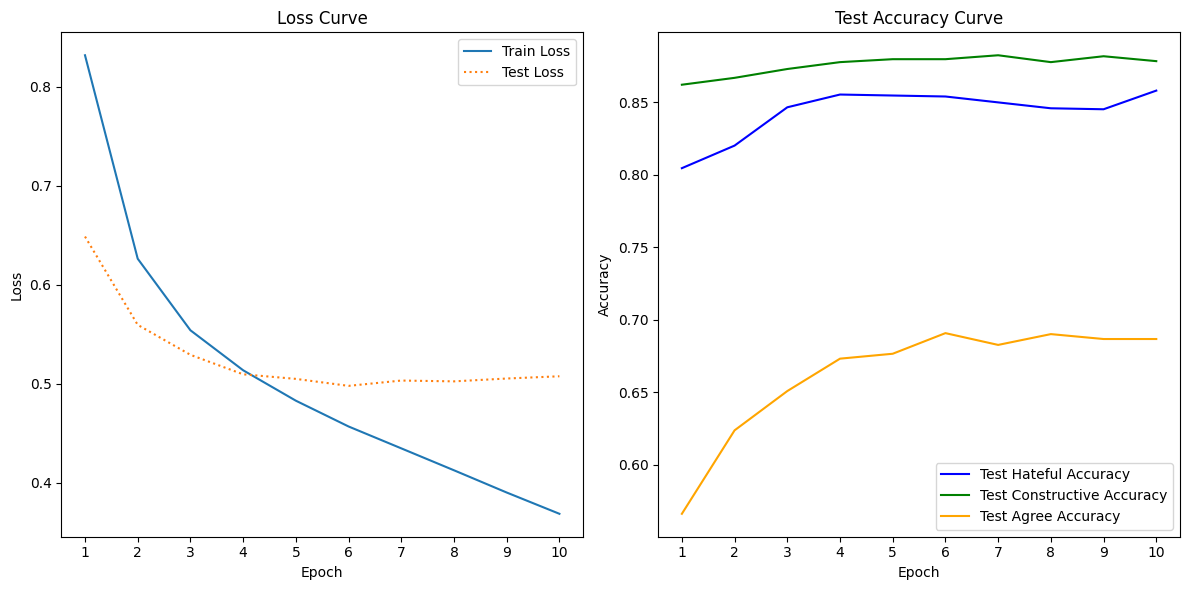

In [7]:
## --- Imports ---

# Data processing 
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
# Modelling 
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import random

'''
Implements a random seed throughout that makes the result replicable. However label smoothing can not be enabled as this messes up the seed
'''

def set_seed(seed):
    # Python's built-in random module
    random.seed(seed)
    
    # Numpy's random module
    np.random.seed(seed)
    
    # PyTorch seed for CPU
    torch.manual_seed(seed)
    
    # PyTorch seed for all GPU devices (if using CUDA)
    torch.cuda.manual_seed_all(seed)
    
    # Make sure to disable CuDNN's non-deterministic optimizations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(1)



'''
The following code will fine-tune a model on a English labeled dataset to predict 1 label for each class where:

class refers to the different ''categories'' of the data. In this case there are 3 classes: 'rep_hateful', 'rep_constructive', 'rep_agree', and 

label refers to the type of each class. In this case there are 9 labels in total, where a text can have only 1 label for each class, e.g. 'Hateful', 'Not Constructive', 'Disagree'. Thus a text cannot have both the labels 'Hateful' and 'Not Hateful'

Explanatory comments are integrated to guide users through the code structure and functionality.
'''

# Set device, run on gpu if available 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Load/prepare data
train_df=eng_dan_data.sample(frac=0.8,random_state=2000) #take 80% of new df
test_df=eng_dan_data.drop(train_df.index) #take new df but to create test but drop the ones that are in train


# Set tokenizer and batch size
tokenizer = AutoTokenizer.from_pretrained("cardiffnlp/twitter-xlm-roberta-base")
batch_size = 16


# Map labels to numeric values for each of the classes 
label_mappings = {
    'rep_hateful': {'Not Hateful': 0, 'Hateful': 1, 'Unclassifiable Hateful': 2},
    'rep_constructive': {'Not Constructive': 0, 'Constructive': 1, 'Unclassifiable Constructive': 2},
    'rep_agree': {'Agree': 0, 'Disagree': 1, 'Unclear': 2}}
for column, mapping in label_mappings.items():
    train_df[column] = train_df[column].map(mapping)
    test_df[column] = test_df[column].map(mapping)


# Directly extract the necessary columns as a numpy array (already encoded as 0, 1, 2)
train_labels = train_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values
test_labels = test_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values


# Define class
class TextDataset(Dataset):
    def __init__(self, texts, labels_hateful, labels_constructive, labels_agree, tokenizer, max_length = 512):
        self.texts = texts
        self.labels_hateful = labels_hateful
        self.labels_constructive = labels_constructive
        self.labels_agree = labels_agree
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts) # Returns the size of the dataset

    def __getitem__(self, idx):
        text = self.texts[idx]
        # Get labels for each class
        label_hateful = self.labels_hateful[idx]
        label_constructive = self.labels_constructive[idx]
        label_agree = self.labels_agree[idx]

        # Tokenize the text
        encodings = self.tokenizer(
            text,
            padding = "max_length",
            truncation = True,
            max_length = self.max_length,
            return_tensors = "pt")

        # Return input tensors and labels for each class
        return {
            "input_ids": encodings["input_ids"].squeeze(),  # Squeeze function converts to the correct shape
            "attention_mask": encodings["attention_mask"].squeeze(),
            "labels_hateful": torch.tensor(label_hateful, dtype = torch.long), # Convert labels into tensor format
            "labels_constructive": torch.tensor(label_constructive, dtype = torch.long), # Long function to get 64-bit integer numbers 
            "labels_agree": torch.tensor(label_agree, dtype = torch.long)}


# Prepare datasets using the TextDataset class we definedd
train_dataset = TextDataset(
    texts = train_df['rep_text'].tolist(),
    labels_hateful = train_labels[:, 0], # Get first column from train_labels array
    labels_constructive = train_labels[:, 1],
    labels_agree = train_labels[:, 2],
    tokenizer = tokenizer)

test_dataset = TextDataset(
    texts = test_df['rep_text'].tolist(),
    labels_hateful = test_labels[:, 0], # Get first column from train_labels array
    labels_constructive = test_labels[:, 1],
    labels_agree = test_labels[:, 2],
    tokenizer = tokenizer)


# Create train and test dataloaders
# Dataset stores the texts and their corresponding labels
# DataLoader wraps an iterable around the Dataset to enable easy access to the texts
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = batch_size)


# Set model 
model = AutoModelForSequenceClassification.from_pretrained("cardiffnlp/twitter-xlm-roberta-base", num_labels = 9) 
model = model.to(device)


# Set criterion: CrossEntropyLoss used for multi output classification. This criterion computes the cross entropy loss between input logits and target
#criterion = nn.CrossEntropyLoss(label_smoothing=0.3)
criterion = nn.CrossEntropyLoss()

# Set optimizer, Adam works well for most tasks
optimizer = optim.AdamW(model.parameters(), lr = 2e-6, weight_decay=1e-1)


# Define learning rete scheduler 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5, min_lr=1e-7)


# Define training process. The model is set up as a multi-output classification task where each label is independently predicted
def train(model, dataloader, criterion, optimizer, device):
    model.train() # Set to train mode
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0 # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class
    
    for batch in tqdm(dataloader, desc = "Training"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels_hateful = batch["labels_hateful"].to(device)
        labels_constructive = batch["labels_constructive"].to(device)
        labels_agree = batch["labels_agree"].to(device)
        
        # Clear out the gradients of all parameters that the optimizer is tracking
        optimizer.zero_grad()
        # Calls the forward pass of the model and processes the input data through the layers of the model
        outputs = model(input_ids, attention_mask = attention_mask)
        
        # Extract logits (raw predictions before applying any activation function)
        # Logits will have a shape of [batch_size, 9] since num_labels = 9
        logits = outputs.logits 

        # Now fetch the logits for each label
        # Split the logits into 3 sets of logits (each corresponding to 1 task with 3 labels)
        logits_hateful = logits[:, :3]           # First 3 logits for the "hateful" task
        logits_constructive = logits[:, 3:6]     # Next 3 logits for the "constructive" task
        logits_agree = logits[:, 6:]             # Last 3 logits for the "agree" task

        # Calculate the loss for each class
        # The criterion (CrossEntropyLoss) applies the softmax function internally to the logits. This transforms the raw logits into probabilities that sum to 1 for each example in the batch. 
        # It then calculates the negative log-likelihood loss based on the true labels
        loss_hateful = criterion(logits_hateful, labels_hateful)
        loss_constructive = criterion(logits_constructive, labels_constructive)
        loss_agree = criterion(logits_agree, labels_agree)

        # Combine the losses (average them)
        loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
        
        # Accumulate the loss as a Python float
        total_loss += loss.item()
        
        # Backward pass and optimizer step
        loss.backward()
        optimizer.step() # Makes the optimizer iterate over all parameters (tensors) it is supposed to update and use their internally stored gradients to update their values.

        # Accuracy calculations
        # Predicts the labels for each task by selecting the label with the highest score (logit)
        preds_hateful = torch.argmax(logits_hateful, dim = 1)
        preds_constructive = torch.argmax(logits_constructive, dim = 1)
        preds_agree = torch.argmax(logits_agree, dim = 1)

        # Calculates how many of the predicted labels are correct and then adds that number to the correct_x counter
        correct_hateful += (preds_hateful == labels_hateful).sum().item()
        correct_constructive += (preds_constructive == labels_constructive).sum().item()
        correct_agree += (preds_agree == labels_agree).sum().item()

        # Keeps track of the total number of texts for each classification task
        total_hateful += labels_hateful.size(0) 
        total_constructive += labels_constructive.size(0)
        total_agree += labels_agree.size(0)

    # Calculate average loss for the train data
    avg_loss_train = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return avg_loss_train, accuracy_hateful, accuracy_constructive, accuracy_agree

    
# Define evaluation process
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set to evaluation mode
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0  # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class

    # Initalize empty list to store predicted labels and true labels
    # These will be used in making the classfication reports
    all_preds_hateful, all_preds_constructive, all_preds_agree = [],[],[]
    all_labels_hateful, all_labels_constructive, all_labels_agree = [],[],[]

    with torch.no_grad(): # Temporarily disable gradient calculations during the forward pass
        # Saves memory and computation because the operations don't need to be tracked for backward propagation.
        # This is crucial during evaluation (inference) because we don't need to update the model parameters—just forward pass predictions.
        for batch in tqdm(dataloader, desc = "Evaluating"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels_hateful = batch["labels_hateful"].to(device)
            labels_constructive = batch["labels_constructive"].to(device)
            labels_agree = batch["labels_agree"].to(device)

            # Calls the forward pass of the model and processes the input data through the layers of the model
            outputs = model(input_ids, attention_mask = attention_mask)
            # Extract logits
            logits = outputs.logits

            # Split the logits for each task
            logits_hateful = logits[:, :3]          
            logits_constructive = logits[:, 3:6] 
            logits_agree = logits[:, 6:]

            # Calculate loss for each task
            loss_hateful = criterion(logits_hateful, labels_hateful)
            loss_constructive = criterion(logits_constructive, labels_constructive)
            loss_agree = criterion(logits_agree, labels_agree)

            # Combine the losses (average them) and store as float
            loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
            total_loss += loss.item()

            # Predicts the labels for each task
            preds_hateful = torch.argmax(logits_hateful, dim=1).cpu().numpy()
            preds_constructive = torch.argmax(logits_constructive, dim=1).cpu().numpy()
            preds_agree = torch.argmax(logits_agree, dim=1).cpu().numpy()

            # Extend the predictions and true labels
            all_preds_hateful.extend(preds_hateful)
            all_preds_constructive.extend(preds_constructive)
            all_preds_agree.extend(preds_agree)

            all_labels_hateful.extend(labels_hateful.cpu().numpy()) # Use labels on CPU for comparison after moving them to device
            all_labels_constructive.extend(labels_constructive.cpu().numpy())
            all_labels_agree.extend(labels_agree.cpu().numpy())

            # Update counts for correctly predicted labels 
            correct_hateful += (preds_hateful == labels_hateful.cpu().numpy()).sum()
            correct_constructive += (preds_constructive == labels_constructive.cpu().numpy()).sum()
            correct_agree += (preds_agree == labels_agree.cpu().numpy()).sum()

            # Update counts for total number of labels for each class 
            total_hateful += labels_hateful.size(0)
            total_constructive += labels_constructive.size(0)
            total_agree += labels_agree.size(0)

    # Calculate average loss for the test data
    avg_loss_test = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return (avg_loss_test, 
            np.array(all_labels_hateful), np.array(all_preds_hateful),
            np.array(all_labels_constructive), np.array(all_preds_constructive),
            np.array(all_labels_agree), np.array(all_preds_agree),
            accuracy_hateful, accuracy_constructive, accuracy_agree)


# --- Setup saving parameters ---
output_dir = "/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/twitter-xlm/model_without_ref/"


## --- Running model ---

# Define the label classes
label_classes = { 
    'rep_hateful': ['Not Hateful', 'Hateful', 'Unclassifiable Hateful'],
    'rep_constructive': ['Not Constructive', 'Constructive', 'Unclassifiable Constructive'],
    'rep_agree': ['Agree', 'Disagree', 'Unclear']
}

train_losses, test_losses = [], [] # Empty lists for storing losses
train_accuracies, test_accuracies = [], [] # Empty lists for storing accuracies


# Number of epochs
num_epochs = 20
# Initialize counter for epoch number
epoch_no = 0 
# Empty lists for storing learning rates
lr_history = []
# Counter to track epochs with no improvement
early_stopping_counter = 0  
# Set best_loss to infinitely high to ensure that the first loss will always be lower
best_loss = float('inf')  
# Initialize best accuracy and best loss
best_avg_accuracy = 0.0
best_model_so_far = None 


for epoch in range(num_epochs):
    epoch_no = epoch + 1
    print(f"Epoch {epoch_no}:")

    # Append and print current learning rate
    lr_history.append(scheduler.get_last_lr()[0])
    print(f"Being trained with a learning rate of {lr_history[-1]}")

    # -- Train model -- 
    avg_loss_train, train_acc_hateful, train_acc_constructive, train_acc_agree = train(model, train_dataloader, criterion, optimizer, device)
    train_losses.append(avg_loss_train) # Store training loss
    train_accuracies.append((train_acc_hateful, train_acc_constructive, train_acc_agree)) # Store accuracies for training
    
    # -- Test model -- 
    avg_loss_test, test_true_labels_hateful, test_pred_labels_hateful,test_true_labels_constructive, test_pred_labels_constructive, test_true_labels_agree, test_pred_labels_agree, test_acc_hateful, test_acc_constructive, test_acc_agree =  evaluate(model, test_dataloader, criterion, device)
    test_losses.append(avg_loss_test) # Store test loss
    test_accuracies.append((test_acc_hateful, test_acc_constructive, test_acc_agree)) # Store accuracies for testing

    # Update learning rate with scheduler
    scheduler.step(avg_loss_test)

    # Save accuracy
    avg_accuracy = round((test_acc_hateful+test_acc_constructive + test_acc_agree)/3,3)
    
    # Print results 
    print(f"  Train Loss: {avg_loss_train:.4f}, test Loss: {avg_loss_test:.4f}")
    print(f"  Hateful Accuracy: {test_acc_hateful:.4f}, Constructive Accuracy: {test_acc_constructive:.4f}, Agree Accuracy: {test_acc_agree:.4f}")
    print(f"  Average Accuracy: {avg_accuracy:.4f}")


    # Save the model if it achieves the best average accuracy and stop running if accuracy has not improved 
    if avg_accuracy > best_avg_accuracy:
        best_avg_accuracy = avg_accuracy
        best_model_epoch = epoch_no 

        # Save true and predicted labels for the best model
        best_labels = {
            "hateful": {"true": test_true_labels_hateful, "pred": test_pred_labels_hateful},
            "constructive": {"true": test_true_labels_constructive, "pred": test_pred_labels_constructive},
            "agree": {"true": test_true_labels_agree, "pred": test_pred_labels_agree}
        }
        
        best_model_so_far = model.state_dict()
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1  # Increment the counter if no improvement
        if early_stopping_counter >= 4:
            print("Stopping because early stopping has been triggered.")
            break  # Stop training if patience is exceeded


# Save only the 1 best model off all when all epochs are done
checkpoint_filename = "model_epoch_{epoch}.pt"
best_model_path = output_dir + checkpoint_filename.format(epoch = best_model_epoch)
torch.save(best_model_so_far, best_model_path)


# --- Plotting results ---

# Generate confusion matrix for each class for the best model
for class_name, labels in label_classes.items():

    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Compute the confusion matrix 
        matrix = confusion_matrix(class_true, class_pred)
        # Plot and save the confusion matrix
        plt.figure(figsize = (10,10))
        sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels,
                    yticklabels=labels)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Confusion Matrix for {class_name}_')
        plt.savefig(f'{output_dir}/confusion_matrix_{class_name}_epoch_{best_model_epoch}.png')
        plt.close()


# Generate classification report for each class for the best model
for class_name, labels in label_classes.items():
    
    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Generate classification report as a dictionary
        report = classification_report(class_true, 
                                    class_pred, 
                                    target_names=labels, 
                                    output_dict=True)
        
        # Save the classification report to a text file
        report_filename = f"{output_dir}/classification_report_{class_name}_epoch_{best_model_epoch}.txt"
        with open(report_filename, "w") as f:
            f.write(classification_report(class_true, class_pred, target_names=labels))


plt.figure(figsize = (12,6))

# Loss and accuracy plot over epochs
# Loss curve
plt.subplot(1,2,1)
plt.plot(np.arange(1, epoch_no+1), train_losses, label = "Train Loss")
plt.plot(np.arange(1, epoch_no+1), test_losses, label = "Test Loss", linestyle = ":")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Accuracy on test set (colored by class)
plt.subplot(1, 2, 2)
plt.plot(np.arange(1, epoch_no+1), [x[0] for x in test_accuracies], label = "Test Hateful Accuracy", color = "blue")
plt.plot(np.arange(1, epoch_no+1), [x[1] for x in test_accuracies], label = "Test Constructive Accuracy", color = "green")
plt.plot(np.arange(1, epoch_no+1), [x[2] for x in test_accuracies], label = "Test Agree Accuracy", color = "orange")
plt.title("Test Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Save and show 
plt.savefig(output_dir+f'accuracy_and_loss_curce_plot_epoch_{best_model_epoch}.png')
plt.tight_layout()
plt.show()



##### With ref

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 66586.98it/s]
XLMRobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-xlm-roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.decoder.bias            | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.decoder.weight          | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized 

Epoch 1:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:03<00:00, 25.14it/s]


  Train Loss: 0.8551, test Loss: 0.7384
  Hateful Accuracy: 0.7788, Constructive Accuracy: 0.7530, Agree Accuracy: 0.5142
  Average Accuracy: 0.6820
Epoch 2:
Being trained with a learning rate of 2e-06


Evaluating: 100%|██████████| 93/93 [00:03<00:00, 25.10it/s]


  Train Loss: 0.7134, test Loss: 0.6561
  Hateful Accuracy: 0.7788, Constructive Accuracy: 0.8254, Agree Accuracy: 0.5670
  Average Accuracy: 0.7240
Epoch 3:
Being trained with a learning rate of 2e-06


... (20 outputs left out)

Evaluating: 100%|██████████| 93/93 [00:03<00:00, 25.16it/s]


  Train Loss: 0.3990, test Loss: 0.5587
  Hateful Accuracy: 0.8241, Constructive Accuracy: 0.8579, Agree Accuracy: 0.6746
  Average Accuracy: 0.7860
Epoch 14:
Being trained with a learning rate of 1e-06


Evaluating: 100%|██████████| 93/93 [00:03<00:00, 25.23it/s]


  Train Loss: 0.3907, test Loss: 0.5633
  Hateful Accuracy: 0.8234, Constructive Accuracy: 0.8518, Agree Accuracy: 0.6820
  Average Accuracy: 0.7860
Stopping because early stopping has been triggered.


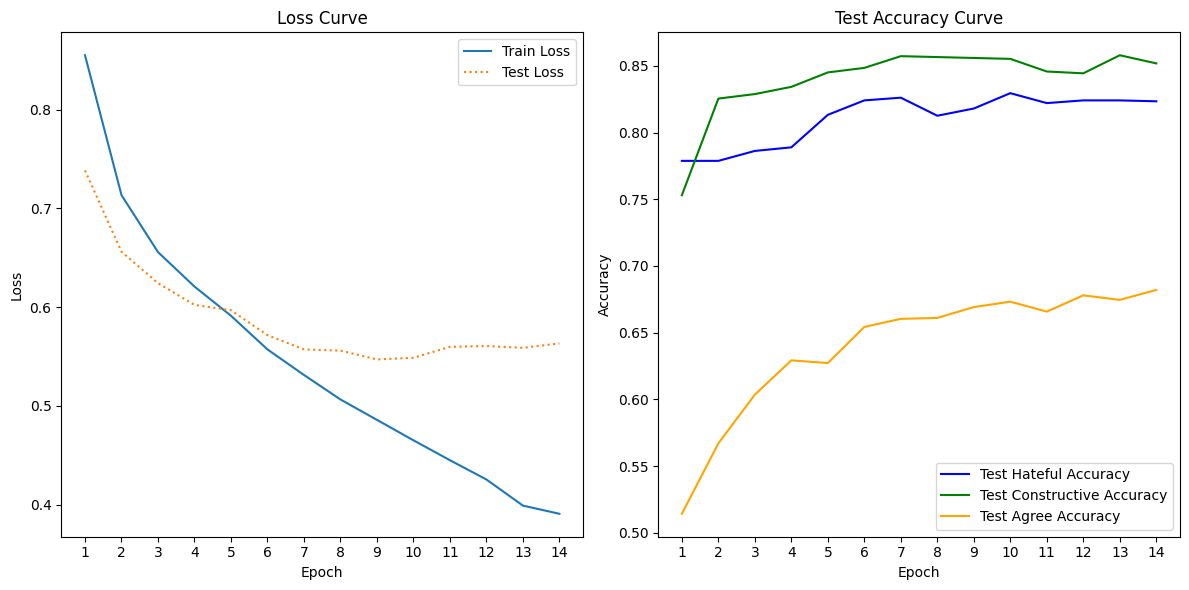

In [8]:
## --- Imports ---

# Data processing 
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
# Modelling 
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import random

'''
Implements a random seed throughout that makes the result replicable. However label smoothing can not be enabled as this messes up the seed
'''

def set_seed(seed):
    # Python's built-in random module
    random.seed(seed)
    
    # Numpy's random module
    np.random.seed(seed)
    
    # PyTorch seed for CPU
    torch.manual_seed(seed)
    
    # PyTorch seed for all GPU devices (if using CUDA)
    torch.cuda.manual_seed_all(seed)
    
    # Make sure to disable CuDNN's non-deterministic optimizations
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(1)



'''
The following code will fine-tune a model on a English labeled dataset to predict 1 label for each class where:

class refers to the different ''categories'' of the data. In this case there are 3 classes: 'rep_hateful', 'rep_constructive', 'rep_agree', and 

label refers to the type of each class. In this case there are 9 labels in total, where a text can have only 1 label for each class, e.g. 'Hateful', 'Not Constructive', 'Disagree'. Thus a text cannot have both the labels 'Hateful' and 'Not Hateful'

Explanatory comments are integrated to guide users through the code structure and functionality.
'''

# Set device, run on gpu if available 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Load/prepare data
train_df=eng_dan_data.sample(frac=0.8,random_state=2000) #take 80% of new df
test_df=eng_dan_data.drop(train_df.index) #take new df but to create test but drop the ones that are in train


# Set tokenizer and batch size
tokenizer = AutoTokenizer.from_pretrained("cardiffnlp/twitter-xlm-roberta-base")
batch_size = 16


# Map labels to numeric values for each of the classes 
label_mappings = {
    'rep_hateful': {'Not Hateful': 0, 'Hateful': 1, 'Unclassifiable Hateful': 2},
    'rep_constructive': {'Not Constructive': 0, 'Constructive': 1, 'Unclassifiable Constructive': 2},
    'rep_agree': {'Agree': 0, 'Disagree': 1, 'Unclear': 2}}
for column, mapping in label_mappings.items():
    train_df[column] = train_df[column].map(mapping)
    test_df[column] = test_df[column].map(mapping)


# Directly extract the necessary columns as a numpy array (already encoded as 0, 1, 2)
train_labels = train_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values
test_labels = test_df[['rep_hateful', 'rep_constructive', 'rep_agree']].values


# Define class
class TextDataset(Dataset):
    def __init__(self, texts,ref_texts, labels_hateful, labels_constructive, labels_agree, tokenizer, max_length = 512):
        self.texts = texts
        self.ref_texts = ref_texts
        self.labels_hateful = labels_hateful
        self.labels_constructive = labels_constructive
        self.labels_agree = labels_agree
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts) # Returns the size of the dataset

    def __getitem__(self, idx):

        text = self.texts[idx]
        ref_text = self.ref_texts[idx]

        label_hateful = self.labels_hateful[idx]
        label_constructive = self.labels_constructive[idx]
        label_agree = self.labels_agree[idx]

        #the tokenizer automatically inserts the separator tokens
        encodings = self.tokenizer(
            ref_text,
            text,
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt"
        )

        return {
            "input_ids": encodings["input_ids"].squeeze(),
            "attention_mask": encodings["attention_mask"].squeeze(),
            "labels_hateful": torch.tensor(label_hateful, dtype=torch.long),
            "labels_constructive": torch.tensor(label_constructive, dtype=torch.long),
            "labels_agree": torch.tensor(label_agree, dtype=torch.long),
        }


# Prepare datasets using the TextDataset class we definedd
train_dataset = TextDataset(
    texts = train_df['rep_text'].tolist(),
    ref_texts = train_df['ref_text'].tolist(),
    labels_hateful = train_labels[:, 0], # Get first column from train_labels array
    labels_constructive = train_labels[:, 1],
    labels_agree = train_labels[:, 2],
    tokenizer = tokenizer)

test_dataset = TextDataset(
    texts = test_df['rep_text'].tolist(),
    ref_texts = test_df['ref_text'].tolist(),
    labels_hateful = test_labels[:, 0], # Get first column from train_labels array
    labels_constructive = test_labels[:, 1],
    labels_agree = test_labels[:, 2],
    tokenizer = tokenizer)


# Create train and test dataloaders
# Dataset stores the texts and their corresponding labels
# DataLoader wraps an iterable around the Dataset to enable easy access to the texts
train_dataloader = DataLoader(train_dataset, batch_size = batch_size, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = batch_size)


# Set model
model = AutoModelForSequenceClassification.from_pretrained("cardiffnlp/twitter-xlm-roberta-base", num_labels = 9)

# Set criterion: CrossEntropyLoss used for multi output classification. This criterion computes the cross entropy loss between input logits and target
#criterion = nn.CrossEntropyLoss(label_smoothing=0.3)
criterion = nn.CrossEntropyLoss()

# Set optimizer, Adam works well for most tasks
optimizer = optim.AdamW(model.parameters(), lr = 2e-6, weight_decay=1e-1) 
# Define learning rete scheduler 
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.5, min_lr=1e-7)


# Define training process. The model is set up as a multi-output classification task where each label is independently predicted
def train(model, dataloader, criterion, optimizer, device):
    model.train() # Set to train mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0 # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class
    
    for batch in tqdm(dataloader, desc = "Training"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels_hateful = batch["labels_hateful"].to(device)
        labels_constructive = batch["labels_constructive"].to(device)
        labels_agree = batch["labels_agree"].to(device)
        
        # Clear out the gradients of all parameters that the optimizer is tracking
        optimizer.zero_grad()
        # Calls the forward pass of the model and processes the input data through the layers of the model
        outputs = model(input_ids, attention_mask = attention_mask)
        
        # Extract logits (raw predictions before applying any activation function)
        # Logits will have a shape of [batch_size, 9] since num_labels = 9
        logits = outputs.logits 

        # Now fetch the logits for each label
        # Split the logits into 3 sets of logits (each corresponding to 1 task with 3 labels)
        logits_hateful = logits[:, :3]           # First 3 logits for the "hateful" task
        logits_constructive = logits[:, 3:6]     # Next 3 logits for the "constructive" task
        logits_agree = logits[:, 6:]             # Last 3 logits for the "agree" task

        # Calculate the loss for each class
        # The criterion (CrossEntropyLoss) applies the softmax function internally to the logits. This transforms the raw logits into probabilities that sum to 1 for each example in the batch. 
        # It then calculates the negative log-likelihood loss based on the true labels
        loss_hateful = criterion(logits_hateful, labels_hateful)
        loss_constructive = criterion(logits_constructive, labels_constructive)
        loss_agree = criterion(logits_agree, labels_agree)

        # Combine the losses (average them)
        loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
        
        # Accumulate the loss as a Python float
        total_loss += loss.item()
        
        # Backward pass and optimizer step
        loss.backward()
        optimizer.step() # Makes the optimizer iterate over all parameters (tensors) it is supposed to update and use their internally stored gradients to update their values.

        # Accuracy calculations
        # Predicts the labels for each task by selecting the label with the highest score (logit)
        preds_hateful = torch.argmax(logits_hateful, dim = 1)
        preds_constructive = torch.argmax(logits_constructive, dim = 1)
        preds_agree = torch.argmax(logits_agree, dim = 1)

        # Calculates how many of the predicted labels are correct and then adds that number to the correct_x counter
        correct_hateful += (preds_hateful == labels_hateful).sum().item()
        correct_constructive += (preds_constructive == labels_constructive).sum().item()
        correct_agree += (preds_agree == labels_agree).sum().item()

        # Keeps track of the total number of texts for each classification task
        total_hateful += labels_hateful.size(0) 
        total_constructive += labels_constructive.size(0)
        total_agree += labels_agree.size(0)

    # Calculate average loss for the train data
    avg_loss_train = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return avg_loss_train, accuracy_hateful, accuracy_constructive, accuracy_agree

    
# Define evaluation process
def evaluate(model, dataloader, criterion, device):
    model.eval()  # Set to evaluation mode
    model.to(device) # Allocate model to defined device 
    
    total_loss = 0.0  # Initialize counter for total_loss as a float
    correct_hateful, correct_constructive, correct_agree = 0, 0, 0  # Initialize counter for correctly predicted labels for each class
    total_hateful, total_constructive, total_agree = 0, 0, 0 # Initialize counter for total number of labels for each class

    # Initalize empty list to store predicted labels and true labels
    # These will be used in making the classfication reports
    all_preds_hateful, all_preds_constructive, all_preds_agree = [],[],[]
    all_labels_hateful, all_labels_constructive, all_labels_agree = [],[],[]

    with torch.no_grad(): # Temporarily disable gradient calculations during the forward pass
        # Saves memory and computation because the operations don't need to be tracked for backward propagation.
        # This is crucial during evaluation (inference) because we don't need to update the model parameters—just forward pass predictions.
        for batch in tqdm(dataloader, desc = "Evaluating"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels_hateful = batch["labels_hateful"].to(device)
            labels_constructive = batch["labels_constructive"].to(device)
            labels_agree = batch["labels_agree"].to(device)

            # Calls the forward pass of the model and processes the input data through the layers of the model
            outputs = model(input_ids, attention_mask = attention_mask)
            # Extract logits
            logits = outputs.logits

            # Split the logits for each task
            logits_hateful = logits[:, :3]          
            logits_constructive = logits[:, 3:6] 
            logits_agree = logits[:, 6:]

            # Calculate loss for each task
            loss_hateful = criterion(logits_hateful, labels_hateful)
            loss_constructive = criterion(logits_constructive, labels_constructive)
            loss_agree = criterion(logits_agree, labels_agree)

            # Combine the losses (average them) and store as float
            loss = (loss_hateful + loss_constructive + loss_agree) / 3.0
            total_loss += loss.item()

            # Predicts the labels for each task
            preds_hateful = torch.argmax(logits_hateful, dim=1).cpu().numpy()
            preds_constructive = torch.argmax(logits_constructive, dim=1).cpu().numpy()
            preds_agree = torch.argmax(logits_agree, dim=1).cpu().numpy()

            # Extend the predictions and true labels
            all_preds_hateful.extend(preds_hateful)
            all_preds_constructive.extend(preds_constructive)
            all_preds_agree.extend(preds_agree)

            all_labels_hateful.extend(labels_hateful.cpu().numpy()) # Use labels on CPU for comparison after moving them to device
            all_labels_constructive.extend(labels_constructive.cpu().numpy())
            all_labels_agree.extend(labels_agree.cpu().numpy())

            # Update counts for correctly predicted labels 
            correct_hateful += (preds_hateful == labels_hateful.cpu().numpy()).sum()
            correct_constructive += (preds_constructive == labels_constructive.cpu().numpy()).sum()
            correct_agree += (preds_agree == labels_agree.cpu().numpy()).sum()

            # Update counts for total number of labels for each class 
            total_hateful += labels_hateful.size(0)
            total_constructive += labels_constructive.size(0)
            total_agree += labels_agree.size(0)

    # Calculate average loss for the test data
    avg_loss_test = total_loss / len(dataloader)

    # Calculate accuracy for each task based on number of correctly predicted 
    accuracy_hateful = correct_hateful / total_hateful
    accuracy_constructive = correct_constructive / total_constructive
    accuracy_agree = correct_agree / total_agree

    return (avg_loss_test, 
            np.array(all_labels_hateful), np.array(all_preds_hateful),
            np.array(all_labels_constructive), np.array(all_preds_constructive),
            np.array(all_labels_agree), np.array(all_preds_agree),
            accuracy_hateful, accuracy_constructive, accuracy_agree)



# --- Setup saving parameters ---
output_dir = "/work/IdaHeleneDencker#2808/Redoing_counterspeech_classifier/twitter-xlm/model_with_ref/"


## --- Running model ---

# Define the label classes
label_classes = { 
    'rep_hateful': ['Not Hateful', 'Hateful', 'Unclassifiable Hateful'],
    'rep_constructive': ['Not Constructive', 'Constructive', 'Unclassifiable Constructive'],
    'rep_agree': ['Agree', 'Disagree', 'Unclear']
}

train_losses, test_losses = [], [] # Empty lists for storing losses
train_accuracies, test_accuracies = [], [] # Empty lists for storing accuracies


# Number of epochs
num_epochs = 20
# Initialize counter for epoch number
epoch_no = 0 
# Empty lists for storing learning rates
lr_history = []
# Counter to track epochs with no improvement
early_stopping_counter = 0  
# Set best_loss to infinitely high to ensure that the first loss will always be lower
best_loss = float('inf')  
# Initialize best accuracy and best loss
best_avg_accuracy = 0.0
best_model_so_far = None 


for epoch in range(num_epochs):
    epoch_no = epoch + 1
    print(f"Epoch {epoch_no}:")

    # Append and print current learning rate
    lr_history.append(scheduler.get_last_lr()[0])
    print(f"Being trained with a learning rate of {lr_history[-1]}")

    # -- Train model -- 
    avg_loss_train, train_acc_hateful, train_acc_constructive, train_acc_agree = train(model, train_dataloader, criterion, optimizer, device)
    train_losses.append(avg_loss_train) # Store training loss
    train_accuracies.append((train_acc_hateful, train_acc_constructive, train_acc_agree)) # Store accuracies for training
    
    # -- Test model -- 
    avg_loss_test, test_true_labels_hateful, test_pred_labels_hateful,test_true_labels_constructive, test_pred_labels_constructive, test_true_labels_agree, test_pred_labels_agree, test_acc_hateful, test_acc_constructive, test_acc_agree =  evaluate(model, test_dataloader, criterion, device)
    test_losses.append(avg_loss_test) # Store test loss
    test_accuracies.append((test_acc_hateful, test_acc_constructive, test_acc_agree)) # Store accuracies for testing

    # Update learning rate with scheduler
    scheduler.step(avg_loss_test)

    # Save accuracy
    avg_accuracy = round((test_acc_hateful+test_acc_constructive + test_acc_agree)/3,3)
    
    # Print results 
    print(f"  Train Loss: {avg_loss_train:.4f}, test Loss: {avg_loss_test:.4f}")
    print(f"  Hateful Accuracy: {test_acc_hateful:.4f}, Constructive Accuracy: {test_acc_constructive:.4f}, Agree Accuracy: {test_acc_agree:.4f}")
    print(f"  Average Accuracy: {avg_accuracy:.4f}")


    # Save the model if it achieves the best average accuracy and stop running if accuracy has not improved 
    if avg_accuracy > best_avg_accuracy:
        best_avg_accuracy = avg_accuracy
        best_model_epoch = epoch_no 

        # Save true and predicted labels for the best model
        best_labels = {
            "hateful": {"true": test_true_labels_hateful, "pred": test_pred_labels_hateful},
            "constructive": {"true": test_true_labels_constructive, "pred": test_pred_labels_constructive},
            "agree": {"true": test_true_labels_agree, "pred": test_pred_labels_agree}
        }
        
        best_model_so_far = model.state_dict()
        early_stopping_counter = 0
    else:
        early_stopping_counter += 1  # Increment the counter if no improvement
        if early_stopping_counter >= 4:
            print("Stopping because early stopping has been triggered.")
            break  # Stop training if patience is exceeded


# Save only the 1 best model off all when all epochs are done
checkpoint_filename = "model_epoch_{epoch}.pt"
best_model_path = output_dir + checkpoint_filename.format(epoch = best_model_epoch)
torch.save(best_model_so_far, best_model_path)


# --- Plotting results ---

# Generate confusion matrix for each class for the best model
for class_name, labels in label_classes.items():

    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Compute the confusion matrix 
        matrix = confusion_matrix(class_true, class_pred)
        # Plot and save the confusion matrix
        plt.figure(figsize = (10,10))
        sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
                    xticklabels=labels,
                    yticklabels=labels)
        plt.xlabel('Predicted')
        plt.ylabel('Actual')
        plt.title(f'Confusion Matrix for {class_name}_')
        plt.savefig(f'{output_dir}/confusion_matrix_{class_name}_epoch_{best_model_epoch}.png')
        plt.close()


# Generate classification report for each class for the best model
for class_name, labels in label_classes.items():
    
    # Adjust the key names to match with those in best_labels
    class_key = class_name.split('_')[1]  # e.g., 'rep_hateful' -> 'hateful'
    
    if class_key in best_labels:
        # Fetch the true and predicted labels for the current class
        class_true = best_labels[class_key]["true"]
        class_pred = best_labels[class_key]["pred"]
        
        # Generate classification report as a dictionary
        report = classification_report(class_true, 
                                    class_pred, 
                                    target_names=labels, 
                                    output_dict=True)
        
        # Save the classification report to a text file
        report_filename = f"{output_dir}/classification_report_{class_name}_epoch_{best_model_epoch}.txt"
        with open(report_filename, "w") as f:
            f.write(classification_report(class_true, class_pred, target_names=labels))


plt.figure(figsize = (12,6))

# Loss and accuracy plot over epochs
# Loss curve
plt.subplot(1,2,1)
plt.plot(np.arange(1, epoch_no+1), train_losses, label = "Train Loss")
plt.plot(np.arange(1, epoch_no+1), test_losses, label = "Test Loss", linestyle = ":")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Accuracy on test set (colored by class)
plt.subplot(1, 2, 2)
plt.plot(np.arange(1, epoch_no+1), [x[0] for x in test_accuracies], label = "Test Hateful Accuracy", color = "blue")
plt.plot(np.arange(1, epoch_no+1), [x[1] for x in test_accuracies], label = "Test Constructive Accuracy", color = "green")
plt.plot(np.arange(1, epoch_no+1), [x[2] for x in test_accuracies], label = "Test Agree Accuracy", color = "orange")
plt.title("Test Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.xticks(np.arange(1, epoch_no+1)) #show x-axis as integers

# Save and show 
plt.savefig(output_dir+f'accuracy_and_loss_curce_plot_epoch_{best_model_epoch}.png')
plt.tight_layout()
plt.show()


